[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/02_SEMMA_Flight_Delays/notebooks/SEMMA_Flight_Disruption.ipynb)

# Will My Flight Be Disrupted Tomorrow? A SEMMA Study of 11.7 Million US Flights
**CMPE 255 · Assignment 4 · Project 2 of 3**

This project follows SAS's **SEMMA** methodology: **S**ample → **E**xplore → **M**odify → **M**odel → **A**ssess, plus a scoring/deployment step. SEMMA has no business-understanding stage of its own, so a short **front pass** comes first. It frames the problem, checks the data, and freezes the train/validation/test partition before any modeling.

*Data: [US Flight Delays & Cancellations 2025-2026](https://www.kaggle.com/datasets/samuelpombourcq/us-flight-delays-and-cancellations-2025-2026) (Samuel_Pbq, CC0), from the US Bureau of Transportation Statistics (BTS) On-Time Performance table. 11,730,351 flights, Jan 2025 – Aug 2026.*

## 0. Setup

In [1]:
import os, subprocess, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"
if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/02_SEMMA_Flight_Delays")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/Assignment4/requirements.txt"], check=True)
    # The 314 MB flight file comes from Kaggle: add your kaggle.json (or KAGGLE_USERNAME / KAGGLE_KEY) first.
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "src")); os.chdir(PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/02_SEMMA_Flight_Delays


In [2]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn, lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from flightdelay import config
from flightdelay.data import load_flights, period, assert_no_test_targets
from flightdelay.features import schedule_features, previous_day_rates
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__} | lightgbm {lgb.__version__}")

python 3.12.14 | pandas 3.1.0 | sklearn 1.9.1 | lightgbm 4.7.0


---
# Front pass · Problem framing, data checks, frozen partition

> **Revision 2**, after critic round 1 (6/10; `critiques/frontpass_round1.md`). Main changes:
> - a **target leak** is removed (the tail-number feature, whose missingness means "cancelled");
> - previous-day rates now use a **17:00 decision clock**;
> - **two baselines** (schedule rule and day-before rule) instead of one;
> - the primary metric is **per-day** top-k lift, with day-clustered intervals;
> - a **summer check** runs inside the non-test data;
> - a seal guard is added, and the Hawaiian → Alaska recoding is handled.

> SEMMA starts at *Sample*. The course slides note that, unlike CRISP-DM, it has no business-understanding step. This front pass supplies the minimum: who decides what, with which information, and how success is judged. It also checks the data before any modeling.

### F.1 Problem
**Hypothetical stakeholder:** the customer-care team of a travel-booking service (or an airline). At **17:00 local the day before**, it can proactively handle passengers on about **2% of tomorrow's flights** (~380 of ~19k a day): rebooking tight connections, sending alerts, staffing help desks.

**Decision:** which of tomorrow's flights fall in that top 2% by risk.

**Allowed inputs:** the published schedule, plus outcomes of flights **scheduled to land by 17:00** on previous days. Nothing observed later.

**Target, `disrupted`:** arrived 15+ minutes late, cancelled, or diverted. That's 23.7% of flights in train + validation; the test months stay sealed.

**Scored population (assumption A-pop):** flights *with* a tail number. Every flight without one is cancelled (22,511 of 22,511 in train + validation). We *assume* these are early cancellations the team already knows about, but nothing in the data shows they were cancelled before 17:00 the day before, and they cluster on storm days. So Assess reports results **both ways**: with them excluded, and with them scored as disrupted.

**Success (Assess stage, sealed test months):**
- **Primary:** per-day top-2% precision and lift (precision ÷ that day's disruption rate), averaged over days. Top-10% is also reported.
- **Secondary:** pooled ROC-AUC / PR-AUC and calibration.
- **Always compared with two simple rules:**
  - schedule rule: airline × departure-hour history;
  - **day-before rule:** the mean of yesterday's origin, destination and carrier disruption rates.
- Exact targets are set in the Sample stage, from validation only.

### F.2 Data checks (all 11.7M flights; structure only, no target statistics on the test months)

In [3]:
cols = ["flight_date", "day_of_week", "airline_code", "tail_number", "flight_number", "origin", "dest",
        "sched_dep_time", "sched_arr_time", "dep_delay", "dep_del15", "arr_delay", "arr_del15", "cancelled", "diverted",
        "sched_elapsed_time", "distance", "carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
d = load_flights(columns=cols)
d["period"] = period(d["flight_date"])
operated = (d["cancelled"] == 0) & (d["diverted"] == 0)
late = operated & (d["arr_delay"] >= 15)
causes = d.loc[late, ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]].sum(axis=1)
dd = d[d["dep_delay"].notna()]
dup = d[d.duplicated(["flight_date", "airline_code", "flight_number", "origin", "sched_dep_time"], keep=False)]
per_day = d.groupby("flight_date").size()
checks = pd.Series({
    "flights": len(d),
    "date range": f"{d.flight_date.min().date()} → {d.flight_date.max().date()}",
    "flights per day (min / median / max)": f"{per_day.min():,} / {int(per_day.median()):,} / {per_day.max():,}",
    "carriers / airports": f"{d.airline_code.nunique()} / {pd.concat([d.origin.astype(str), d.dest.astype(str)]).nunique()}",
    "arr_del15 == (arr_delay ≥ 15), operated": f"{(d.loc[operated, 'arr_del15'] == (d.loc[operated, 'arr_delay'] >= 15)).mean():.4%}",
    "dep_del15 == (dep_delay ≥ 15)": f"{(dd.dep_del15 == (dd.dep_delay >= 15)).mean():.4%}",
    "delay causes sum to arr_delay (late flights)": f"{(causes == d.loc[late, 'arr_delay']).mean():.4%}",
    "cancelled flights that still have a dep_delay (left gate, then cancelled)": int((d.cancelled.eq(1) & d.dep_delay.notna()).sum()),
    "sched_elapsed_time missing / ≤ 0": f"{int(d.sched_elapsed_time.isna().sum())} / {int((d.sched_elapsed_time <= 0).sum())}",
    "sched_dep_time == 2400 (midnight)": int((d.sched_dep_time == 2400).sum()),
    "duplicate flight keys (rows)": f"{len(dup)} rows: " + ", ".join(f"{r.airline_code} {r.flight_number} {r.flight_date.date()}" for r in dup.head(2).itertuples()),
    "missing tail_number (train + valid): all cancelled?": f"{d.loc[d.tail_number.isna() & d.period.isin(['train', 'valid'])].shape[0]:,} rows, "
        f"{d.loc[d.tail_number.isna() & d.period.isin(['train', 'valid']), 'cancelled'].mean():.1%} cancelled",
})
display(checks.to_frame("value"))

,value
flights,11730351
date range,2025-01-01 → 2026-08-31
flights per day (min / median / max),"11,001 / 19,677 / 21,576"
carriers / airports,14 / 361
"arr_del15 == (arr_delay ≥ 15), operated",100.0000%
dep_del15 == (dep_delay ≥ 15),100.0000%
delay causes sum to arr_delay (late flights),99.9944%
"cancelled flights that still have a dep_delay (left gate, then cancelled)",8243
sched_elapsed_time missing / ≤ 0,4 / 14
sched_dep_time == 2400 (midnight),1


In [4]:
# Carrier mix by period (counts only): HA stops after 2025; its network is reported as AS from 2026; NK winds down
mix = d.groupby(["period", "airline_code"], observed=True).size().unstack("period")[["train", "valid", "test"]]
hawaii = d[d.airline_code.eq("AS") & (d.origin.astype(str).isin(["HNL", "OGG", "KOA", "LIH", "ITO"]) | d.dest.astype(str).isin(["HNL", "OGG", "KOA", "LIH", "ITO"]))]
display(mix.loc[["AS", "HA", "NK"]].assign(note=["HA network added from 2026-01", "last flight 2025-12-31", "last flight 2026-05-01"]))
print("AS flights touching Hawaii per month: 2025 mean", int(hawaii[hawaii.flight_date.dt.year == 2025].groupby(hawaii.flight_date.dt.to_period("M")).size().mean()),
      "| 2026 mean", int(hawaii[hawaii.flight_date.dt.year == 2026].groupby(hawaii.flight_date.dt.to_period("M")).size().mean()))

period,train,valid,test,note
airline_code,,,,
AS,245588.0,105464.0,122142.0,HA network added from 2026-01
HA,80084.0,NaN,NaN,last flight 2025-12-31
NK,194515.0,46848.0,354.0,last flight 2026-05-01


AS flights touching Hawaii per month: 2025 mean 1384 | 2026 mean 8063


**What this shows:**
- **The table is internally consistent.** Delay flags match delay minutes; delay causes add up on 99.994% of late flights.
- **Small, explained exceptions:**
  - 8,243 cancelled flights still have a `dep_delay`: they left the gate before being cancelled, as documented.
  - 4 flights are missing `sched_elapsed_time` and 14 have a value ≤ 0. Decision: drop them in Modify.
  - 1 flight is scheduled at 2400 (midnight); it gets departure hour 23.
  - The 1 duplicate key is two F9 rows with null delays; one is kept.
- **Days look complete,** including August 2026. BTS can revise its latest month, which is noted as a limitation.
- **Carrier changes are real and handled:**
  - Hawaiian's network is reported under Alaska from 2026, so `carrier` maps HA → AS (`config.CARRIER_GROUP`).
  - Spirit winds down, with its last flights on 2026-05-01 (the test period's first day).
- **Missing tail numbers = cancellations.** Every flight without a tail number is cancelled, so the v1 feature `leg_of_day` (missing for exactly these flights) **leaked the target**. Those flights are now excluded from the scored population, and no feature is derived from `tail_number`.

### F.3 Frozen partition and seal

In [5]:
part = d.groupby("period").agg(flights=("flight_date", "size"), first=("flight_date", "min"), last=("flight_date", "max"))
dev = assert_no_test_targets(d[d["period"].isin(["train", "valid"])])     # guard: no target stats on test
part["disrupted rate"] = dev.groupby("period")["disrupted"].mean()
display(part.loc[["train", "valid", "test"]])
print(f"train + valid disruption rate: {dev['disrupted'].mean():.3f}")

,flights,first,last,disrupted rate
period,,,,
train,7001619,2025-01-01,2025-12-31,0.236627
valid,2269061,2026-01-01,2026-04-30,0.236289
test,2459671,2026-05-01,2026-08-31,NaN


train + valid disruption rate: 0.237


| Partition | Months | Use |
|---|---|---|
| Train | Jan–Dec 2025 | Fit |
| Validation | Jan–Apr 2026 | Tuning, model choice, targets |
| *Summer check* | *train Jan–Apr 2025 → validate May–Aug 2025* | *Season-matched check, inside the non-test data, because the test is a summer* |
| **Test (sealed)** | **May–Aug 2026** | **Scored once in Assess**, after refitting on train + validation (refit policy) |

*Disclosures:*
- The v1 data check printed quarterly disruption rates for the whole period (test months included).
- The v1 report quoted an all-period rate (24.4%). That's now replaced by the train + validation rate.
- Neither informs any modeling choice. `assert_no_test_targets` now guards the target statistics in F.3 and F.5.

### F.4 Leakage audit
| Column / file | Known at 17:00 the day before? | Use |
|---|---|---|
| Schedule: date, weekday, carrier, flight number, route, scheduled dep/arr times, distance, scheduled elapsed time | Yes | Features |
| Scheduled departures per origin-hour / origin-day | Yes. BTS reports flights scheduled for the day, including later cancellations | Features |
| **`tail_number` and anything derived from it** | **No.** It's the aircraft actually flown, and it's missing exactly when the flight is cancelled | **Excluded** (v1 leak) |
| `month` | Yes, but it encodes one training year's weather | Excluded (lagged seasonal rates may come in Modify) |
| Yesterday's disruption rates by origin / destination / carrier, **from flights scheduled to land by 17:00** | Yes | Day-before features (`DECISION_CUTOFF_HHMM`) |
| Flight-day outcomes (dep/arr times and delays, taxi, cancelled, diverted, delay causes, actual/air time) | No | Target only |
| `daily_airport_stats.csv` | Only lagged and cut off at 17:00, which it isn't (it's full-day) | Excluded |
| `airlines.csv`, `airports.csv` departures/arrivals | **No.** They aggregate the whole period, test included | Excluded (`FORBIDDEN_FILES`) |

### F.5 Feasibility (two validation windows; test untouched)

In [6]:
from flightdelay.features import SCHEDULE_FEATURES, DAY_BEFORE_FEATURES
sched = assert_no_test_targets(d[d["period"].isin(["train", "valid"])]).drop_duplicates(
    ["flight_date", "airline_code", "flight_number", "origin", "sched_dep_time"])
# schedule counts and previous-day rates on the FULL schedule (all flights, incl. tail-less cancellations), then filter
feat = previous_day_rates(schedule_features(sched))
feat = feat[feat["tail_number"].notna() & feat["sched_elapsed_time"].gt(0)]   # scored population (assumption A-pop)
for col in ["carrier", "origin", "dest"]:
    feat[col] = feat[col].astype(str)

def per_day(dates, y, s, frac):
    """Per-day top-frac precision and lift (precision / that day's rate), one value per day."""
    prec, lift = [], []
    for _, idx in pd.Series(np.arange(len(y))).groupby(np.asarray(dates)):
        yi, si = y[idx.to_numpy()], s[idx.to_numpy()]
        k = max(1, int(round(frac * len(yi))))
        top = np.argsort(-si, kind="stable")[:k]
        if yi.mean() > 0:
            prec.append(yi[top].mean()); lift.append(yi[top].mean() / yi.mean())
    return np.array(prec), np.array(lift)

def block_bootstrap(x, block=7, n=2000, seed=config.SEED):
    """90% interval of the mean of a daily series, resampling 7-day blocks (daily rates are autocorrelated)."""
    rng = np.random.default_rng(seed)
    blocks = [x[i:i + block] for i in range(0, len(x), block)]
    means = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean() for _ in range(n)]
    return np.quantile(means, [0.05, 0.95])

def evaluate(train_rng, valid_rng, label):
    tr_all = feat[feat.flight_date.between(*train_rng)]
    va = feat[feat.flight_date.between(*valid_rng)].copy()
    tr = tr_all.sample(400_000, random_state=config.SEED).copy()
    for col in ["carrier", "origin", "dest"]:
        cats = pd.Index(sorted(tr[col].unique()))
        tr[col] = pd.Categorical(tr[col], categories=cats); va[col] = pd.Categorical(va[col].where(va[col].isin(cats)), categories=cats)
    y = va["disrupted"].to_numpy()
    hist = tr_all.groupby(["carrier", "dep_hour"], observed=True)["disrupted"].mean()
    sched_rule = np.array([hist.get(k, np.nan) for k in zip(va["carrier"].astype(str), va["dep_hour"])])
    scores = {"schedule rule (carrier × dep-hour history)": np.where(np.isnan(sched_rule), tr_all["disrupted"].mean(), sched_rule),
              "day-before rule (mean of yesterday's 3 rates)": va[DAY_BEFORE_FEATURES].mean(axis=1).fillna(tr_all["disrupted"].mean()).to_numpy()}
    for name, feats in [("LightGBM, schedule only", SCHEDULE_FEATURES), ("LightGBM, schedule + day-before", SCHEDULE_FEATURES + DAY_BEFORE_FEATURES)]:
        m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=config.SEED).fit(tr[feats], tr["disrupted"])
        scores[name] = m.predict_proba(va[feats])[:, 1]
    rows, daily = [], {}
    for name, s in scores.items():
        daily[name] = {f: per_day(va["flight_date"], y, s, f) for f in config.TOP_FRACTIONS}
        rows.append({"window": label, "scorer": name, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                     **{f"per-day top-{int(f * 100)}% precision": daily[name][f][0].mean() for f in config.TOP_FRACTIONS},
                     **{f"per-day top-{int(f * 100)}% lift": daily[name][f][1].mean() for f in config.TOP_FRACTIONS}})
    # model vs the BEST simple rule in this window, 7-day block bootstrap
    rules = ["schedule rule (carrier × dep-hour history)", "day-before rule (mean of yesterday's 3 rates)"]
    best = max(rules, key=lambda r: daily[r][0.02][1].mean())
    gap = daily["LightGBM, schedule + day-before"][0.02][1] - daily[best][0.02][1]
    lo, hi = block_bootstrap(gap)
    print(f"{label}: base rate {y.mean():.3f}, {len(gap)} days. Best simple rule: {best}. Model − best rule, per-day top-2% lift: "
          f"{gap.mean():+.2f} (90% 7-day-block interval {lo:+.2f} to {hi:+.2f}); model better on {np.mean(gap > 0):.0%} of days")
    return rows

res = pd.DataFrame(evaluate((config.TRAIN_START, config.TRAIN_END), (config.VALID_START, config.VALID_END), "main: 2025 → Jan–Apr 2026")
                   + evaluate(config.SUMMER_CHECK["train"], config.SUMMER_CHECK["valid"], "summer check: Jan–Apr 2025 → May–Aug 2025"))
display(res.set_index(["window", "scorer"]).round(3))

main: 2025 → Jan–Apr 2026: base rate 0.233, 120 days. Best simple rule: day-before rule (mean of yesterday's 3 rates). Model − best rule, per-day top-2% lift: +0.30 (90% 7-day-block interval +0.18 to +0.40); model better on 71% of days


summer check: Jan–Apr 2025 → May–Aug 2025: base rate 0.272, 123 days. Best simple rule: schedule rule (carrier × dep-hour history). Model − best rule, per-day top-2% lift: +0.19 (90% 7-day-block interval +0.10 to +0.28); model better on 67% of days


ROC-AUC  \
window                                    scorer                                                   
main: 2025 → Jan–Apr 2026                 schedule rule (carrier × dep-hour history)       0.610   
                                          day-before rule (mean of yesterday's 3 rates)    0.628   
                                          LightGBM, schedule only                          0.641   
                                          LightGBM, schedule + day-before                  0.685   
summer check: Jan–Apr 2025 → May–Aug 2025 schedule rule (carrier × dep-hour history)       0.661   
                                          day-before rule (mean of yesterday's 3 rates)    0.583   
                                          LightGBM, schedule only                          0.659   
                                          LightGBM, schedule + day-before                  0.675   

                                                                                         PR-AUC  \
window                                    scorer                                                  
main: 2025 → Jan–Apr 2026                 schedule rule (carrier × dep-hour history)      0.304   
                                          day-before rule (mean of yesterday's 3 rates)   0.359   
                                          LightGBM, schedule only                         0.345   
                                          LightGBM, schedule + day-before                 0.400   
summer check: Jan–Apr 2025 → May–Aug 2025 schedule rule (carrier × dep-hour history)      0.394   
                                          day-before rule (mean of yesterday's 3 rates)   0.330   
                                          LightGBM, schedule only                         0.398   
                                          LightGBM, schedule + day-before                 0.414   

                                                                                         per-day top-2% precision  \
window                                    scorer                                                                    
main: 2025 → Jan–Apr 2026                 schedule rule (carrier × dep-hour history)                        0.357   
                                          day-before rule (mean of yesterday's 3 rates)                     0.421   
                                          LightGBM, schedule only                                           0.447   
                                          LightGBM, schedule + day-before                                   0.488   
summer check: Jan–Apr 2025 → May–Aug 2025 schedule rule (carrier × dep-hour history)                        0.471   
                                          day-before rule (mean of yesterday's 3 rates)                     0.365   
                                          LightGBM, schedule only                                           0.499   
                                          LightGBM, schedule + day-before                                   0.516   

                                                                                         per-day top-10% precision  \
window                                    scorer                                                                     
main: 2025 → Jan–Apr 2026                 schedule rule (carrier × dep-hour history)                         0.342   
                                          day-before rule (mean of yesterday's 3 rates)                      0.368   
                                          LightGBM, schedule only                                            0.385   
                                          LightGBM, schedule + day-before                                    0.412   
summer check: Jan–Apr 2025 → May–Aug 2025 schedule rule (carrier × dep-hour history)                         0.447   
                                          day-before rule (mean of yesterday's 3 rates)             

**Feasibility verdict (honest numbers after removing the leak and applying the 17:00 cutoff):**

| Per-day top-2% lift (precision) | Main (→ Jan–Apr 2026) | Summer check (→ May–Aug 2025) |
|---|---|---|
| Schedule rule (carrier × dep-hour history) | 1.56 (0.36) | **1.74 (0.47)** |
| Day-before rule (yesterday's rates) | **1.89 (0.42)** | 1.39 (0.37) |
| LightGBM, schedule only | 1.98 (0.45) | 1.85 (0.50) |
| LightGBM, schedule + day-before | **2.19 (0.49)** | **1.93 (0.52)** |
| *Model − best simple rule (90% 7-day-block interval)* | *+0.30 (+0.18 to +0.40); better on 71% of days* | *+0.19 (+0.10 to +0.28); better on 67% of days* |

- **The best simple rule depends on the season.**
  - In winter–spring the day-before rule is strong. In summer it ranks flights within a day poorly (AUC 0.58), and the schedule pattern wins.
  - The daily disruption rate is somewhat less persistent in summer (day-to-day correlation 0.58 vs 0.69, per critic round 2). That's a *measured* difference, and the cause (e.g. local thunderstorms) is a hypothesis for Explore.
  - So the benchmark for every target is the **best of the two simple rules in that window**, not a fixed one.
- **The model beats both in both windows, but modestly:**
  - main window, vs the day-before rule: +0.30 per-day lift;
  - summer, vs the schedule rule: +0.19.
  - Both 7-day-block intervals exclude 0.
  - The v1 headline ("2.3× vs 1.5×") came from the leak, the uncut previous-day rates and an unfair baseline.
- **Implications for the SEMMA stages:**
  - *Sample* sets targets against the best simple rule.
  - *Modify* adds features that help in summer (lagged rates at hub level, the time-of-day bank structure, multi-day history).
  - *Assess* (a summer test) uses the summer-check window as its closest preview.


---
# Sample

> In SAS Enterprise Miner, *Sample* means the **Input Data**, **Sampling** and **Data Partition** nodes: get to the data, draw a sample that is statistically representative of it, and split it into the roles the later stages use. This section follows the structure of SAS's own best-practices paper, *Data Mining and the Case for Sampling* (in `resources/`): **access → sample size → draw → check → partition**.

**Why sample at all, with 11.7M rows on a laptop?** The SAS paper's case for sampling is that a well-drawn sample loses almost no information, and the time saved goes into exploring and comparing more models. SEMMA's Model stage fits four model families (regression, decision tree, neural network, gradient boosting) and tunes each, and the neural network in particular is slow on millions of rows. Whether that saving is actually free here is an **empirical question**, so S.2 answers it with a learning curve. If the curve said that only the full data reaches full quality, the honest answer would be "don't sample" (the paper's *When sampling should not be used*).

**Not everything is sampled.** The decision is a *per-day* ranking: every evening the care team ranks *all* of tomorrow's flights. So:
- **model fitting** uses the sample;
- **scoring** (validation, summer check, test) always uses **every flight of every day**, as the SAS paper does when it uses the chosen model "to score the entire database";
- **population context features** (scheduled congestion, yesterday's rates) are computed on the full schedule *before* sampling. They describe the day each flight belongs to, which the care team sees in full.

**Pre-registered before any learning curve ran** (`config.py`, Sample block): the strata, the size grid, the number of repeats, the selection rule for the sample size and the acceptance criteria for representativeness. One change was made after a 1-repeat smoke test (25k and 400k rows only) and **before** the real run. With a fixed number of trees, LightGBM over-fits small samples, which would mix up "too few rows" with "too little regularization". So tree counts are set by early stopping on a held-out 10% of each training sample (never the validation months). **Revision 2 (critic round 1, M1):** that holdout is now a random 10% of whole **days**. Revision 1 held out random rows from the same days, which rewarded memorising day-level inputs and kept the 3,000-tree cap binding in every large fit. LightGBM's curve was re-run in full, and the revision-1 table is kept as `sample_learning_curve_rev1_rowES.csv`.


### S.1 Access: the sampling frame
The frame is the front-pass scored population in **train + validation** (Jan 2025 – Apr 2026). The sealed test months are counted here and never sampled.


In [7]:
# S.1 Access: the population the sample is drawn from. Train + validation only; test months are counted, never sampled.
from flightdelay import lcurve, sampling
from flightdelay.features import DEDUP_KEY, build_feature_frame

d["row_id"] = np.arange(len(d), dtype="int32")    # row position in flights.parquet (Kaggle version pinned): a stable flight id
dev_raw = assert_no_test_targets(d[d["period"].isin(["train", "valid"])])
pop = build_feature_frame(dev_raw)            # schedule counts + previous-day rates on the FULL schedule, then A-pop filter
pop["year_month"] = pop["flight_date"].dt.to_period("M").astype(str)
pop["period"] = period(pop["flight_date"])
assert len(pop) == len(feat) and pop["disrupted"].sum() == feat["disrupted"].sum()   # same frame as front-pass F.5

dedup = dev_raw.drop_duplicates(DEDUP_KEY)
steps = pd.DataFrame([
    ("All flights (Jan 2025 – Aug 2026)", len(d)),
    ("− test months May–Aug 2026 (sealed; scored once in Assess, never sampled)", -int((d["period"] == "test").sum())),
    ("= train + validation flights", len(dev_raw)),
    ("− duplicate flight key", len(dedup) - len(dev_raw)),
    ("− no tail number (all cancelled; assumption A-pop)", -int(dedup["tail_number"].isna().sum())),
    ("− sched_elapsed_time missing or ≤ 0", -int((dedup["tail_number"].notna() & ~dedup["sched_elapsed_time"].gt(0)).sum())),
    ("= scored population (sampling frame)", len(pop)),
], columns=["step", "flights"]).set_index("step")
display(steps.style.format("{:,}"))
print(pop.groupby("period").agg(flights=("disrupted", "size"), disrupted=("disrupted", "mean"), days=("flight_date", "nunique")).round(4))
print(f"In memory: {pop.memory_usage(deep=True).sum() / 1e9:.1f} GB for {pop.shape[1]} columns")


,flights
step,
All flights (Jan 2025 – Aug 2026),"11,730,351"
"− test months May–Aug 2026 (sealed; scored once in Assess, never sampled)","-2,459,671"
= train + validation flights,"9,270,680"
− duplicate flight key,-1
− no tail number (all cancelled; assumption A-pop),"-22,510"
− sched_elapsed_time missing or ≤ 0,-14
= scored population (sampling frame),"9,248,154"


        flights  disrupted  days
period                          
train   6989113     0.2353   365
valid   2259041     0.2329   120
In memory: 1.7 GB for 34 columns


**The sampling frame:** 9,248,154 flights (train 6,989,113 over 365 days; validation 2,259,041 over 120 days), disruption rate 23.5% / 23.3%. It matches the front-pass F.5 frame exactly (asserted). In memory it's 1.7 GB with all 34 columns. That's workable on a laptop, but every model fit and every tuning step multiplies it, which is the practical case for sampling that S.2 tests.


### S.2 Sample size: a learning curve, the SAS way
The SAS paper's case study draws repeated samples at several sizes (0.03% to 20%), fits the same model to each and compares mean accuracy with 95% confidence limits. If the means don't differ meaningfully, the small sample is enough. This study does the same with this project's decision metric:

| Setting | Value |
|---|---|
| Sizes | 25k, 50k, 100k, 200k, 400k, 800k, 1.6M, 3.2M training rows, plus the **full training window** |
| Repeats | 5 stratified samples per size (seeds 42–46, nested within a seed); the full window is refit 3 times (seeds 42–44), which gives the noise floor. Shortfalls are reported with a Welch 95% interval (revision 2, critic M3) |
| Models | the front-pass LightGBM (63 leaves); a higher-capacity LightGBM (255 leaves), to test whether a bigger model needs more rows; a one-hot logistic regression |
| Windows | **main** (train 2025 → validate Jan–Apr 2026) and **summer check** (Jan–Apr 2025 → May–Aug 2025, whose pool is only 2.2M rows) |
| Scoring | per-day top-2% lift (primary) and pooled ROC-AUC on the **full** validation window |
| Rule (pre-registered) | n\*_w = smallest size whose mean shortfall vs the full window is ≤ 0.02 lift **and** ≤ 0.002 AUC, for **both** LightGBM capacities. Sampling rate f = max over windows of n\*_w / N_w, rounded **up** to a whole percent |


In [8]:
# S.2 How big must the sample be? Pre-registered learning curve (config: LC_SIZES, LC_REPS, LC_DELTA_*).
# Each window: 5 nested stratified samples per size (seeds 42..46) + the full window refit 3x (seeds 42..44),
# each scored on the FULL validation window. LightGBM trees chosen by early stopping on 10% of the training sample.
# Revision 2 (critic round 1, M1): LightGBM early stopping now holds out whole DAYS (it held out random rows, which let
# the model memorise day-level inputs and kept the 3,000-tree cap binding). LightGBM was re-run in full (5 reps, 3 full
# refits, both windows); the logistic regression has no early stopping, so its revision-1 rows are kept and its
# interrupted summer arm completed. Revision-1 table: reports/tables/sample_learning_curve_rev1_rowES.csv.
RUN_LEARNING_CURVE = False     # True: re-run (scripts/run_learning_curve.py). False: load the saved table.
lc_path = config.PROJECT_DIR / "reports" / "tables" / "sample_learning_curve.csv"
lc = lcurve.run(pop) if RUN_LEARNING_CURVE else pd.read_csv(lc_path)
lc["grid"] = lc["grid"].astype(str)

def summarize(lc):
    rows = []
    for (w, m, g), x in lc.groupby(["window", "model", "grid"], sort=False):
        lm, llo, lhi = sampling.mean_ci(x["top2_lift"]); am, alo, ahi = sampling.mean_ci(x["roc_auc"])
        rows.append({"window": w, "model": m, "grid": g, "n": int(x["size"].mean()), "reps": len(x),
                     "lift2": lm, "lift2 lo": llo, "lift2 hi": lhi, "auc": am, "auc lo": alo, "auc hi": ahi,
                     "trees": x["trees"].mean(), "fit+score s": x["seconds"].mean()})
    s = pd.DataFrame(rows)
    full = s[s.grid == "full"].set_index(["window", "model"])
    s["lift2 shortfall"] = s.apply(lambda r: full.loc[(r.window, r.model), "lift2"] - r.lift2, axis=1)
    s["auc shortfall"] = s.apply(lambda r: full.loc[(r.window, r.model), "auc"] - r.auc, axis=1)
    # critic M3: Welch 95% interval of the lift shortfall (size-n repeats vs full-window refits)
    from scipy import stats as _st
    def welch(r):
        a = lc[(lc.window == r.window) & (lc.model == r.model) & (lc.grid == "full")]["top2_lift"]
        b = lc[(lc.window == r.window) & (lc.model == r.model) & (lc.grid == r.grid)]["top2_lift"]
        if r.grid == "full" or len(a) < 2 or len(b) < 2:
            return pd.Series({"lift short lo": np.nan, "lift short hi": np.nan})
        va_, vb_ = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
        df_ = (va_ + vb_) ** 2 / (va_ ** 2 / (len(a) - 1) + vb_ ** 2 / (len(b) - 1))
        h = _st.t.ppf(0.975, df_) * np.sqrt(va_ + vb_)
        return pd.Series({"lift short lo": r["lift2 shortfall"] - h, "lift short hi": r["lift2 shortfall"] + h})
    s = pd.concat([s, s.apply(welch, axis=1)], axis=1)
    return s

lcs = summarize(lc)
show = lcs.assign(**{"per-day top-2% lift [95% CI]": lcs.apply(lambda r: f"{r.lift2:.3f} [{r['lift2 lo']:.3f}, {r['lift2 hi']:.3f}]", axis=1),
                     "ROC-AUC [95% CI]": lcs.apply(lambda r: f"{r.auc:.4f} [{r['auc lo']:.4f}, {r['auc hi']:.4f}]", axis=1)})
display(show.set_index(["window", "model", "n"])[["reps", "per-day top-2% lift [95% CI]", "lift2 shortfall", "lift short lo", "lift short hi",
                                                    "ROC-AUC [95% CI]", "auc shortfall", "trees"]].round(4))
capped = lc[lc.model.str.startswith("LightGBM") & (lc.trees >= 0.99 * lcurve.MAX_TREES)]
print(f"LightGBM fits within 1% of the {lcurve.MAX_TREES:,}-tree cap: {len(capped)} of {int(lc.model.str.startswith('LightGBM').sum())}")


reps per-day top-2% lift [95% CI]  \
window model               n                                            
main   LightGBM 63 leaves  25000       5         1.938 [1.894, 1.981]   
       LightGBM 255 leaves 25000       5         1.941 [1.890, 1.991]   
       LightGBM 63 leaves  50000       5         1.987 [1.963, 2.011]   
       LightGBM 255 leaves 50000       5         1.965 [1.925, 2.004]   
       LightGBM 63 leaves  100000      5         2.036 [2.012, 2.060]   
       LightGBM 255 leaves 100000      5         2.013 [1.995, 2.032]   
       LightGBM 63 leaves  200000      5         2.104 [2.075, 2.132]   
       LightGBM 255 leaves 200000      5         2.073 [2.055, 2.091]   
       LightGBM 63 leaves  400000      5         2.151 [2.119, 2.182]   
       LightGBM 255 leaves 400000      5         2.123 [2.097, 2.149]   
       LightGBM 63 leaves  800000      5         2.203 [2.181, 2.226]   
       LightGBM 255 leaves 800000      5         2.180 [2.162, 2.198]   
       LightGBM 63 leaves  1600000     5         2.217 [2.206, 2.229]   
       LightGBM 255 leaves 1600000     5         2.214 [2.190, 2.239]   
       LightGBM 63 leaves  3200000     5         2.240 [2.217, 2.263]   
       LightGBM 255 leaves 3200000     5         2.232 [2.210, 2.253]   
       LightGBM 63 leaves  6989113     3         2.251 [2.229, 2.273]   
       LightGBM 255 leaves 6989113     3         2.226 [2.206, 2.246]   
summer LightGBM 63 leaves  25000       5         1.861 [1.797, 1.924]   
       LightGBM 255 leaves 25000       5         1.890 [1.818, 1.961]   
       LightGBM 63 leaves  50000       5         1.892 [1.848, 1.937]   
       LightGBM 255 leaves 50000       5         1.893 [1.848, 1.938]   
       LightGBM 63 leaves  100000      5         1.923 [1.883, 1.963]   
       LightGBM 255 leaves 100000      5         1.910 [1.869, 1.950]   
       LightGBM 63 leaves  200000      5         1.938 [1.921, 1.955]   
       LightGBM 255 leaves 200000      5         1.929 [1.907, 1.951]   
       LightGBM 63 leaves  400000      5         1.969 [1.944, 1.994]   
       LightGBM 255 leaves 400000      5         1.931 [1.907, 1.956]   
       LightGBM 63 leaves  800000      5         1.977 [1.940, 2.014]   
       LightGBM 255 leaves 800000      5         1.946 [1.913, 1.978]   
       LightGBM 63 leaves  1600000     5         1.981 [1.946, 2.016]   
       LightGBM 255 leaves 1600000     5         1.941 [1.911, 1.971]   
       LightGBM 63 leaves  2224847     3         1.969 [1.942, 1.996]   
       LightGBM 255 leaves 2224847     3         1.957 [1.927, 1.988]   
main   logistic regression 25000       5         2.088 [2.033, 2.143]   
                           50000       5         2.142 [2.117, 2.166]   
                           100000      5         2.178 [2.164, 2.192]   
                           200000      5         2.216 [2.200, 2.232]   
                           400000      5         2.237 [2.223, 2.251]   
                           800000      5         2.247 [2.239, 2.256]   
                           1600000     5         2.251 [2.245, 2.256]   
                           3200000     5         2.252 [2.245, 2.258]   
                           6989113     1             2.254 [nan, nan]   
summer logistic regression 25000       5         1.876 [1.831, 1.921]   
                           50000       5         1.897 [1.858, 1.935]   
                           100000      5         1.912 [1.878, 1.945]   
                           200000      5         1.926 [1.919, 1.934]   
                           400000      5         1.941 [1.936, 1.945]   
                           800000      5         1.952 [1.947, 1.956]   
                           1600000     5         1.955 [1.951, 1.960]   
                           2224847     1             1.957 [nan, nan]   

                                    lift2 shortfall  lift short lo  \
window model               n                                         
main   LightGBM 63 leaves 

LightGBM fits within 1% of the 3,000-tree cap: 0 of 162


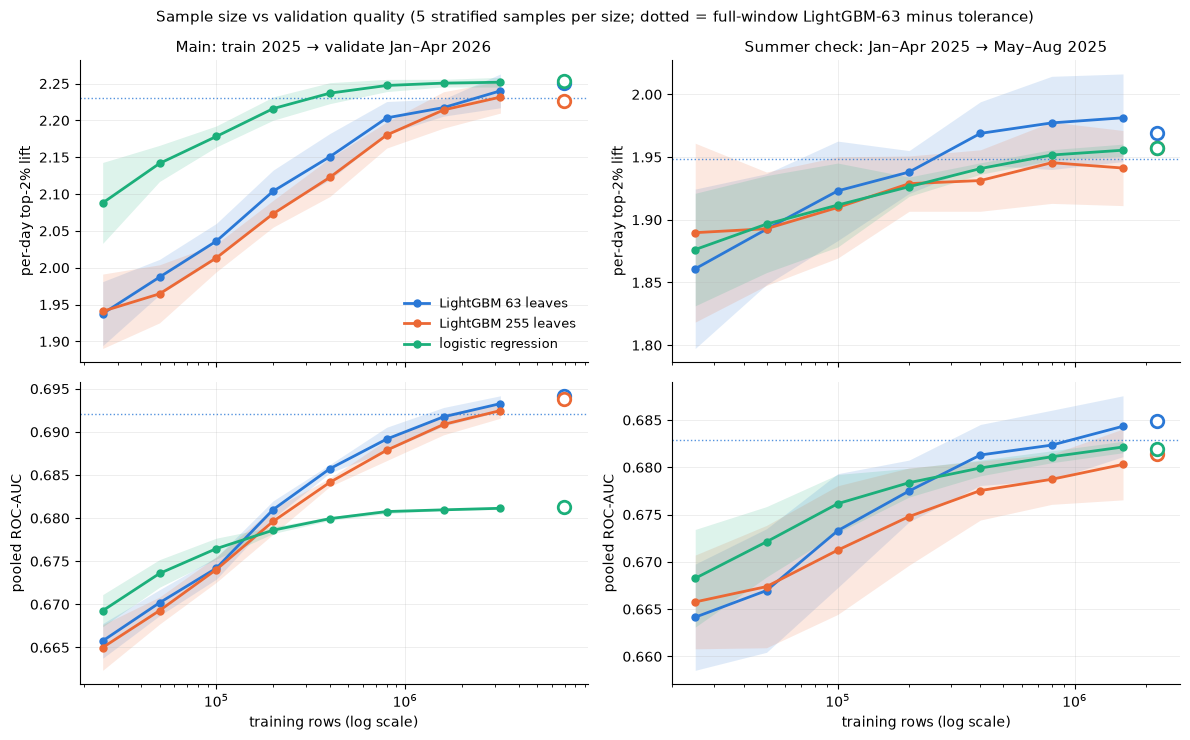

In [9]:
# Learning-curve figure: mean and 95% CI over repeated samples; hollow marker = full training window (mean of refits)
PALETTE = {"LightGBM 63 leaves": "#2a78d6", "LightGBM 255 leaves": "#eb6834", "logistic regression": "#1baf7a"}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex="col")
for j, w in enumerate(["main", "summer"]):
    for i, (col, lab) in enumerate([("lift2", "per-day top-2% lift"), ("auc", "pooled ROC-AUC")]):
        ax = axes[i, j]
        for m, c in PALETTE.items():
            s = lcs[(lcs.window == w) & (lcs.model == m)]
            g, f = s[s.grid != "full"], s[s.grid == "full"]
            ax.plot(g.n, g[col], color=c, lw=2, marker="o", ms=5, label=m)
            ax.fill_between(g.n, g[f"{col} lo"], g[f"{col} hi"], color=c, alpha=0.15, lw=0)
            ax.plot(f.n, f[col], marker="o", ms=9, mfc="white", mec=c, mew=2, ls="none")
            if m.startswith("LightGBM 63"):
                tol = config.LC_DELTA_LIFT if col == "lift2" else config.LC_DELTA_AUC
                ax.axhline(f[col].iloc[0] - tol, color=c, lw=1, ls=":", alpha=0.8)
        ax.set_xscale("log"); ax.grid(alpha=0.25, lw=0.6); ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylabel(lab)
        if i == 0:
            ax.set_title({"main": "Main: train 2025 → validate Jan–Apr 2026",
                          "summer": "Summer check: Jan–Apr 2025 → May–Aug 2025"}[w], fontsize=11)
        if i == 1:
            ax.set_xlabel("training rows (log scale)")
axes[0, 0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("Sample size vs validation quality (5 stratified samples per size; dotted = full-window LightGBM-63 minus tolerance)", fontsize=11)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "sample_learning_curve.png", dpi=150); plt.show()


In [10]:
# Apply the pre-registered rule: n*_w = smallest grid size within tolerance of the full window, both LightGBM capacities
rule_rows = []
for w, x in lcs[lcs.model.str.startswith("LightGBM") & (lcs.grid != "full")].groupby("window", sort=False):
    pool = int(lc.loc[lc.window == w, "pool"].iloc[0])
    by_n = x.groupby("n").agg(worst_lift_short=("lift2 shortfall", "max"), worst_lift_short_hi95=("lift short hi", "max"),
                              worst_auc_short=("auc shortfall", "max"))
    by_n["passes"] = (by_n.worst_lift_short <= config.LC_DELTA_LIFT) & (by_n.worst_auc_short <= config.LC_DELTA_AUC)
    passing = by_n.index[by_n.passes]
    n_star = int(passing.min()) if len(passing) else pool
    larger_all_pass = bool(by_n.loc[by_n.index >= n_star, "passes"].all()) if len(passing) else True
    rule_rows.append({"window": w, "training pool N_w": pool, "n*_w": n_star, "n*_w / N_w": n_star / pool,
                      "all larger sizes also pass": larger_all_pass})
    display(by_n.round(4).rename_axis(f"{w}: n"))
rule = pd.DataFrame(rule_rows).set_index("window")
SAMPLE_RATE = float(np.ceil(100 * rule["n*_w / N_w"].max()) / 100)
display(rule.style.format({"training pool N_w": "{:,}", "n*_w": "{:,}", "n*_w / N_w": "{:.1%}"}))
print(f"Sampling rate f = max_w(n*_w / N_w), rounded up to a whole percent = {SAMPLE_RATE:.0%}")


,worst_lift_short,worst_lift_short_hi95,worst_auc_short,passes
main: n,,,,
25000,0.3132,0.3561,0.0288,False
50000,0.2636,0.3004,0.0245,False
100000,0.2148,0.2395,0.0199,False
200000,0.1528,0.1757,0.0142,False
400000,0.1033,0.1314,0.0096,False
800000,0.0475,0.0707,0.0059,False
1600000,0.0335,0.0508,0.0029,False
3200000,0.0108,0.0346,0.0013,True


,worst_lift_short,worst_lift_short_hi95,worst_auc_short,passes
summer: n,,,,
25000,0.1079,0.1707,0.0207,False
50000,0.0763,0.1201,0.0179,False
100000,0.0473,0.0877,0.0116,False
200000,0.0308,0.0547,0.0074,False
400000,0.0258,0.0536,0.0038,False
800000,0.0116,0.0452,0.0026,False
1600000,0.0159,0.0475,0.0011,True


,training pool N_w,n*_w,n*_w / N_w,all larger sizes also pass
window,,,,
main,"6,989,113","3,200,000",45.8%,True
summer,"2,224,847","1,600,000",71.9%,True


Sampling rate f = max_w(n*_w / N_w), rounded up to a whole percent = 72%


**What the curve says (revision 2, day-grouped early stopping): f = 72%.**

| Window | Training pool N | Smallest size where both LightGBMs pass | n\*/N | Binding criterion just below n\* |
|---|---|---|---|---|
| Main (2025 → Jan–Apr 2026) | 6.99M | **3.2M** (lift shortfall 0.011 / −0.006; AUC 0.0008 / 0.0013) | 46% | at 1.6M both fail: lift (63 leaves 0.034) and AUC (255 leaves 0.0029) |
| Summer (Jan–Apr 2025 → May–Aug 2025) | 2.22M | **1.6M** (lift −0.013 / 0.016; AUC 0.0005 / 0.0011) | 72% | AUC at 800k (0.0025 and 0.0026) |

Sampling rate f = max(46%, 72%), rounded up to a whole percent = **72%**. Gradient boosting trains on a 72% stratified sample of its window.

- **Boosting keeps learning for longer than regression does.** Its lift shortfall shrinks from 0.31 at 25k to about 0.01 at 3.2M (main), and the AUC criterion is what binds. The logistic regression is within 0.017 lift and 0.0014 AUC of its full-window value from **400k** rows in both windows, which is the SAS case study's result. That supports the 800k sample for the simpler models.
- **The shortfalls now have intervals** (Welch 95%, critic M3). The full-window reference is steadier after the fix (3 refits: lift SD 0.009 main and 0.011 summer, against 0.031 in revision 1). But the upper bounds at n\* (0.035 main, 0.048 summer) still exceed 0.02. And the AUC criterion, which binds, has a summer refit SD (0.0024–0.0027) larger than its 0.002 tolerance. **So f = 72% is a call made inside the noise** (critic round 2, M3/N4). It matters little: the champion (logistic regression on 800k) doesn't depend on f, and f = 100% gave the same champion (Model).
- **What changed from revision 1:** with row-random early stopping, every large fit hit the 3,000-tree cap, no size passed, and the rule gave f = 100%. With day-grouped stopping, fits use 25–752 trees, none is capped, and boosting at a given size is better (summer full window 1.97 vs 1.91). Revision 1's "the data is deep, don't sample" was partly an artefact.
- **The regression is the more data-efficient model:** at 800k it matches what boosting reaches only at 1.6–3.2M (main 2.25 vs 2.20 at 800k; summer 1.95 vs 1.98). With the front-pass inputs, the extra capacity of boosting buys little.
- **Caveats:** the curve uses the front-pass (v2) inputs, as pre-registered. The richer v3 inputs might move n\*; Model re-checks boosting at 800k as an equal-n comparison. The summer arm is noisy at small n (non-monotone below 400k).

*Deviations, disclosed:*
- Revision 1 was interrupted in the summer window.
- In revision 2, LightGBM was re-run completely (5 repeats, 3 full refits, both windows). The logistic regression has no early stopping, so its revision-1 rows were kept and its summer arm completed to 5 repeats; it keeps a single full-window refit, since the fit is deterministic.
- The revision-1 table is kept as `sample_learning_curve_rev1_rowES.csv`.


### S.3 Draw the samples
Three **proportional stratified random samples**, all drawn with the Enterprise Miner Sampling node's "stratified" method:
- a **72%** training sample for gradient boosting (rate f from S.2);
- an **800k** training sample for regression, tree and neural network;
- a 5% **exploration** sample, the SAS paper's "wide" sample.
- **Strata:** year-month × carrier group × `disrupted`, about 400 cells, most with thousands of flights. The SAS paper warns against strata "with too many levels (or too few records per level)", which rules out day or airport.
- **Allocation:** proportional, with largest-remainder rounding, so every stratum keeps its population share to within one flight.
- **No oversampling of disruptions.** At a 23.7% base rate the event isn't rare; the SAS paper's enriched sampling (with prior-probability weights) is for rare events like churn at a few percent.

All three are saved to `data/sample/` for the repository. The exploration sample is stored with its columns (about 460k flights) so Explore runs in Colab without the 314 MB file. The two training samples are stored as row ids into the pinned Kaggle file.


In [11]:
# S.3 Draw the samples the later stages actually use (proportional stratified, year-month x carrier x disrupted):
# the gradient-boosting sample at rate f (S.2), an 800k sample for the simpler models (their curve flattens early),
# and a 5% "wide" exploration sample (SAS: explore on a wide sample, model on a deep one).
EXPLORE_RATE = 0.05
exp_smp = sampling.stratified_sample(pop, int(round(EXPLORE_RATE * len(pop))), config.SAMPLE_STRATA, seed=config.SEED + 100).copy()
pop_train = pop[pop.period == "train"]
small = sampling.stratified_sample(pop_train, config.SMALL_MODEL_ROWS, config.SAMPLE_STRATA, seed=config.SEED).copy()
gb = sampling.stratified_sample(pop_train, int(SAMPLE_RATE * len(pop_train)), config.SAMPLE_STRATA, seed=config.SEED).copy()
config.SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
EXPLORE_COLUMNS = (["row_id", "flight_date", "period", "year_month", "day_of_week", "airline_code", "carrier", "flight_number",
                    "origin", "dest", "sched_dep_time", "sched_arr_time", "sched_elapsed_time", "distance", "disrupted",
                    "dep_hour", "arr_hour", "origin_hour_sched", "origin_day_sched"] + DAY_BEFORE_FEATURES
                   # flight-day outcomes, for Explore ONLY (never features; see config.FLIGHT_DAY_OUTCOME_COLUMNS)
                   + ["dep_delay", "arr_delay", "cancelled", "diverted", "carrier_delay", "weather_delay", "nas_delay",
                      "security_delay", "late_aircraft_delay"])
ex = exp_smp[EXPLORE_COLUMNS].sort_values("row_id").reset_index(drop=True)
for c in ["airline_code", "carrier", "origin", "dest", "period", "year_month"]:
    ex[c] = ex[c].astype("category")
ex.to_parquet(config.SAMPLE_DIR / "explore_sample.parquet", index=False, compression="zstd")
small[["row_id"]].sort_values("row_id").to_parquet(config.SAMPLE_DIR / "small_model_sample_row_ids.parquet", index=False, compression="zstd")
gb[["row_id"]].sort_values("row_id").to_parquet(config.SAMPLE_DIR / "boosting_sample_row_ids.parquet", index=False, compression="zstd")
for name, s_, base in [("explore_sample.parquet", exp_smp, pop), ("small_model_sample_row_ids.parquet", small, pop_train),
                       ("boosting_sample_row_ids.parquet", gb, pop_train)]:
    print(f"{name}: {len(s_):,} flights ({len(s_) / len(base):.1%} of its frame) · {(config.SAMPLE_DIR / name).stat().st_size / 1e6:.1f} MB · "
          f"disrupted {s_.disrupted.mean():.4f} (frame {base.disrupted.mean():.4f})")


explore_sample.parquet: 462,408 flights (5.0% of its frame) · 11.5 MB · disrupted 0.2347 (frame 0.2347)
small_model_sample_row_ids.parquet: 800,000 flights (11.4% of its frame) · 2.9 MB · disrupted 0.2353 (frame 0.2353)
boosting_sample_row_ids.parquet: 5,032,161 flights (72.0% of its frame) · 16.4 MB · disrupted 0.2353 (frame 0.2353)


### S.4 Representativeness: does the sample look like its population?
SAS: "the validity of a sample [is] determined by two characteristics — the size of the sample and the quality of the sample". S.2 settled the size. Here the quality is checked against the pre-registered criteria, on variables that were **not** stratified (day, hour, weekday, airports, distance), because the stratified ones match by construction.


In [12]:
# S.4 Is each sample representative of its frame? Pre-registered checks (config: REP_*)
from scipy import stats as sstats
pop["distance_band"] = pd.cut(pop["distance"], [0, 250, 500, 1000, 1500, 2500, 6000]).astype(str)
cat_cols = ["carrier", "year_month", "day_of_week", "dep_hour", "origin", "dest", "distance_band"]
num_cols = ["distance", "sched_elapsed_time", "origin_hour_sched", "origin_day_sched"] + DAY_BEFORE_FEATURES
p3 = 2 * sstats.norm.sf(config.REP_Z_MAX)

def check(smp_, frame):
    smp_ = smp_.assign(distance_band=pop.loc[smp_.index, "distance_band"])
    frame = frame.assign(distance_band=pop.loc[frame.index, "distance_band"])
    cat = pd.DataFrame({c: sampling.categorical_check(smp_[c], frame[c], top=50 if c in ("origin", "dest") else None) for c in cat_cols}).T
    num = pd.DataFrame({c: sampling.numeric_check(smp_[c], frame[c]) for c in num_cols}).T
    rate_rows = []
    for by in ["carrier", "year_month", "flight_date", "dep_hour", "day_of_week", "origin", "dest"]:
        r = sampling.rate_check(smp_, frame, by, "disrupted")
        k = int((r["z"].abs() > config.REP_Z_MAX).sum())
        rate_rows.append({"by": by, "levels": len(r), "max |z|": r["z"].abs().max(), "# |z|>3": k, "expected": len(r) * p3,
                          "binomial p": sstats.binomtest(k, len(r), p3, alternative="greater").pvalue,
                          "max |rate gap| pp": 100 * (r["mean sample"] - r["mean population"]).abs().max()})
    rates = pd.DataFrame(rate_rows).set_index("by")
    per_day_n = smp_.groupby("flight_date").size()
    verdict = {"max |SMD|": num["SMD"].abs().max(), "max share gap pp": cat["max |share gap| (pp)"].max(),
               "days present": f"{per_day_n.size}/{frame.flight_date.nunique()} (min {per_day_n.min():,}/day)",
               "min binomial p": rates["binomial p"].min()}
    verdict["pass"] = (verdict["max |SMD|"] < config.REP_SMD_MAX and verdict["max share gap pp"] < config.REP_GAP_PP_MAX
                       and per_day_n.size == frame.flight_date.nunique() and verdict["min binomial p"] > 0.01)
    return cat, num, rates, verdict

verdicts = {}
for name, s_, frame in [("explore 5%", exp_smp, pop), ("small-model 800k (train 2025)", small, pop_train),
                         (f"boosting {SAMPLE_RATE:.0%} (train 2025)", gb, pop_train)]:
    cat, num, rates, verdicts[name] = check(s_, frame)
    print(f"--- {name}"); display(cat.round(4)); display(num.round(4)); display(rates.round(4))
verdicts = pd.DataFrame(verdicts).T
display(verdicts)
assert verdicts["pass"].all(), "a sample fails a pre-registered representativeness criterion"


--- explore 5%


,levels,max |share gap| (pp),TV distance,chi-square p
carrier,13.0,0.0006,0.0000,1.0000
year_month,16.0,0.0011,0.0000,1.0000
day_of_week,7.0,0.1149,0.0016,0.1265
dep_hour,24.0,0.0749,0.0028,0.2318
origin,51.0,0.0312,0.0032,0.7752
dest,51.0,0.1116,0.0045,0.0340
distance_band,6.0,0.0562,0.0007,0.8793


,population mean,sample mean,SMD,KS D
distance,845.0908,845.1708,0.0001,0.0009
sched_elapsed_time,149.6721,149.6618,-0.0001,0.0009
origin_hour_sched,23.8922,23.8960,0.0002,0.0010
origin_day_sched,362.9831,363.2264,0.0008,0.0011
origin_prev_day,0.1806,0.1803,-0.0019,0.0019
dest_prev_day,0.1803,0.1805,0.0015,0.0015
carrier_prev_day,0.1804,0.1805,0.0001,0.0009


,levels,max |z|,# |z|>3,expected,binomial p,max |rate gap| pp
by,,,,,,
carrier,13,0.0367,0,0.0351,1.0000,0.0168
year_month,16,0.0187,0,0.0432,1.0000,0.0043
flight_date,485,3.4062,1,1.3094,0.7305,3.8804
dep_hour,22,2.7980,0,0.0594,1.0000,5.2840
day_of_week,7,1.4240,0,0.0189,1.0000,0.2373
origin,254,2.7058,0,0.6857,1.0000,12.0437
dest,254,3.4938,1,0.6857,0.4968,14.6130


--- small-model 800k (train 2025)


,levels,max |share gap| (pp),TV distance,chi-square p
carrier,13.0,0.0004,0.0000,1.0000
year_month,12.0,0.0003,0.0000,1.0000
day_of_week,7.0,0.0599,0.0012,0.3351
dep_hour,24.0,0.0424,0.0018,0.4422
origin,51.0,0.0425,0.0027,0.2517
dest,51.0,0.0370,0.0022,0.9385
distance_band,6.0,0.0315,0.0005,0.9252


... (3 outputs left out)

,levels,max |share gap| (pp),TV distance,chi-square p
carrier,13.0,0.0001,0.0000,1.0000
year_month,12.0,0.0001,0.0000,1.0000
day_of_week,7.0,0.0183,0.0002,0.3676
dep_hour,24.0,0.0134,0.0004,0.2313
origin,51.0,0.0082,0.0005,0.5892
dest,51.0,0.0083,0.0006,0.2552
distance_band,6.0,0.0169,0.0003,0.0471


,population mean,sample mean,SMD,KS D
distance,844.3793,844.5202,0.0002,0.0006
sched_elapsed_time,148.8957,148.9130,0.0002,0.0006
origin_hour_sched,23.9732,23.9778,0.0002,0.0005
origin_day_sched,364.0162,364.0645,0.0002,0.0004
origin_prev_day,0.1770,0.1770,0.0001,0.0005
dest_prev_day,0.1768,0.1768,0.0001,0.0005
carrier_prev_day,0.1769,0.1770,0.0001,0.0004


,levels,max |z|,# |z|>3,expected,binomial p,max |rate gap| pp
by,,,,,,
carrier,13,0.0198,0,0.0351,1.0000,0.0012
year_month,12,0.0109,0,0.0324,1.0000,0.0003
flight_date,365,3.2055,1,0.9854,0.6272,0.6004
dep_hour,22,3.1646,1,0.0594,0.0577,0.4545
day_of_week,7,1.9133,0,0.0189,1.0000,0.0504
origin,235,2.7603,0,0.6345,1.0000,2.3390
dest,235,2.7954,0,0.6345,1.0000,1.6411


,max |SMD|,max share gap pp,days present,min binomial p,pass
explore 5%,0.001887,0.114876,485/485 (min 567/day),0.496754,True
small-model 800k (train 2025),0.002475,0.059944,"365/365 (min 1,358/day)",0.133204,True
boosting 72% (train 2025),0.000238,0.018271,"365/365 (min 7,908/day)",0.057742,True


In [13]:
# Why stratify? 20 simple random samples of the same size vs the stratified sample: error in the 208 month × carrier
# disruption rates (the strata cells) and in the daily rates (not stratified, so both designs behave alike).
def cell_errors(s):
    cm = s.groupby(["year_month", "carrier"], observed=True)["disrupted"].mean() - pop.groupby(["year_month", "carrier"], observed=True)["disrupted"].mean()
    dm = s.groupby("flight_date")["disrupted"].mean() - pop.groupby("flight_date")["disrupted"].mean()
    return 100 * np.sqrt(np.nanmean(cm ** 2)), 100 * np.sqrt(np.nanmean(dm ** 2))
srs = np.array([cell_errors(pop.sample(len(exp_smp), random_state=i)) for i in range(20)])
strat = cell_errors(exp_smp)
display(pd.DataFrame({"RMS error, month × carrier rates (pp)": [strat[0], srs[:, 0].mean()],
                      "RMS error, daily rates (pp)": [strat[1], srs[:, 1].mean()]},
                     index=["stratified (explore sample)", "simple random, same size (mean of 20)"]).round(3))


,"RMS error, month × carrier rates (pp)","RMS error, daily rates (pp)"
stratified (explore sample),0.022,1.250
"simple random, same size (mean of 20)",1.179,1.305


**All three samples pass every pre-registered criterion** (the boosting sample, at 72% of its frame, trivially):
- **Numerics:** largest |SMD| is 0.002 (limit 0.05).
- **Categoricals:** largest level-share gap is 0.11 pp (limit 0.5 pp).
- **Days:** every day is present, with at least 567 flights per day in the exploration sample.
- **Target rates by day, hour, weekday and airport:** |z| > 3 occurs no more often than chance. The exploration sample has 2 cases against 2.84 expected; the 800k sample has 2 against 2.40. The pre-registered "except at the chance rate" is applied as: for every variable, a one-sided binomial test of the |z| > 3 count against its chance rate gives p > 0.01.
- **Stratification earns its keep where it applies.** Month × carrier disruption rates are off by 0.02 pp RMS in the stratified sample, against 1.18 pp for simple random samples of the same size. Daily rates aren't stratified and behave the same under both designs (1.25 vs 1.31 pp).


### S.5 Partition and data roles
The partition itself was frozen in the front pass (by time, so the model is always judged on months it hasn't seen). Sample adds which *rows* each role uses.


In [14]:
# S.5 Partition and data roles (the SAS Data Partition node, by time, as frozen in the front pass)
win = lambda a, b: int(pop["flight_date"].between(a, b).sum())
roles = pd.DataFrame([
    ("Gradient boosting: fit", "Jan–Dec 2025", f"{SAMPLE_RATE:.0%} stratified sample", len(gb), "Model"),
    ("Regression / tree / neural net: fit", "Jan–Dec 2025", "800k stratified sample", len(small), "Model"),
    ("Validation", "Jan–Apr 2026", "ALL flights", int((pop.period == "valid").sum()), "Tuning, model choice; per-day ranking needs every flight of a day"),
    ("Summer check", "Jan–Apr 2025 → May–Aug 2025", "fit as above; score ALL", win(*config.SUMMER_CHECK["valid"]), "Season-matched rehearsal of Assess"),
    ("Explore", "Jan 2025 – Apr 2026", "5% stratified sample", len(exp_smp), "Explore (key rates re-checked on the full frame)"),
    ("Refit before Assess", "Jan 2025 – Apr 2026", "as for fitting", int(len(pop)), "Refit policy"),
    ("Test (sealed)", "May–Aug 2026", "ALL flights", int((d.period == "test").sum()), "Scored once in Assess"),
], columns=["role", "months", "rows", "flights", "stage"]).set_index("role")
display(roles.style.format({"flights": "{:,}"}))


,months,rows,flights,stage
role,,,,
Gradient boosting: fit,Jan–Dec 2025,72% stratified sample,"5,032,161",Model
Regression / tree / neural net: fit,Jan–Dec 2025,800k stratified sample,"800,000",Model
Validation,Jan–Apr 2026,ALL flights,"2,259,041","Tuning, model choice; per-day ranking needs every flight of a day"
Summer check,Jan–Apr 2025 → May–Aug 2025,fit as above; score ALL,"2,446,647",Season-matched rehearsal of Assess
Explore,Jan 2025 – Apr 2026,5% stratified sample,"462,408",Explore (key rates re-checked on the full frame)
Refit before Assess,Jan 2025 – Apr 2026,as for fitting,"9,248,154",Refit policy
Test (sealed),May–Aug 2026,ALL flights,"2,459,671",Scored once in Assess


**Assess targets, pre-registered now from validation-period evidence only (`config.py`):**

| # | Target on the sealed test months (May–Aug 2026) |
|---|---|
| **T1 (must)** | The champion beats the **better of the two simple rules on the test months** in per-day top-2% lift, and the 90% 7-day-block bootstrap interval of the daily gap is above 0 |
| **T2 (target)** | That gap is ≥ **+0.15** lift. The front-pass summer rehearsal gap was +0.19 (90% interval +0.10 to +0.28); a new summer and Spirit's exit argue for less |
| **T3 (robustness)** | T1 still holds when the tail-less cancellations are added back and scored as disrupted (assumption A-pop) |

*Champion rule (fixed now):* the model with the highest per-day top-2% lift averaged over the main and summer-check windows.


---
# Explore

> SEMMA *Explore*: look for trends, relationships and anomalies **in the sample** to refine the ideas behind the model (SAS EM: StatExplore, MultiPlot, Cluster nodes). Explore uses the 5% exploration sample from S.3. Anything that needs every flight of a day (daily rates, airport profiles) uses the full train + validation frame, and test months are never touched.


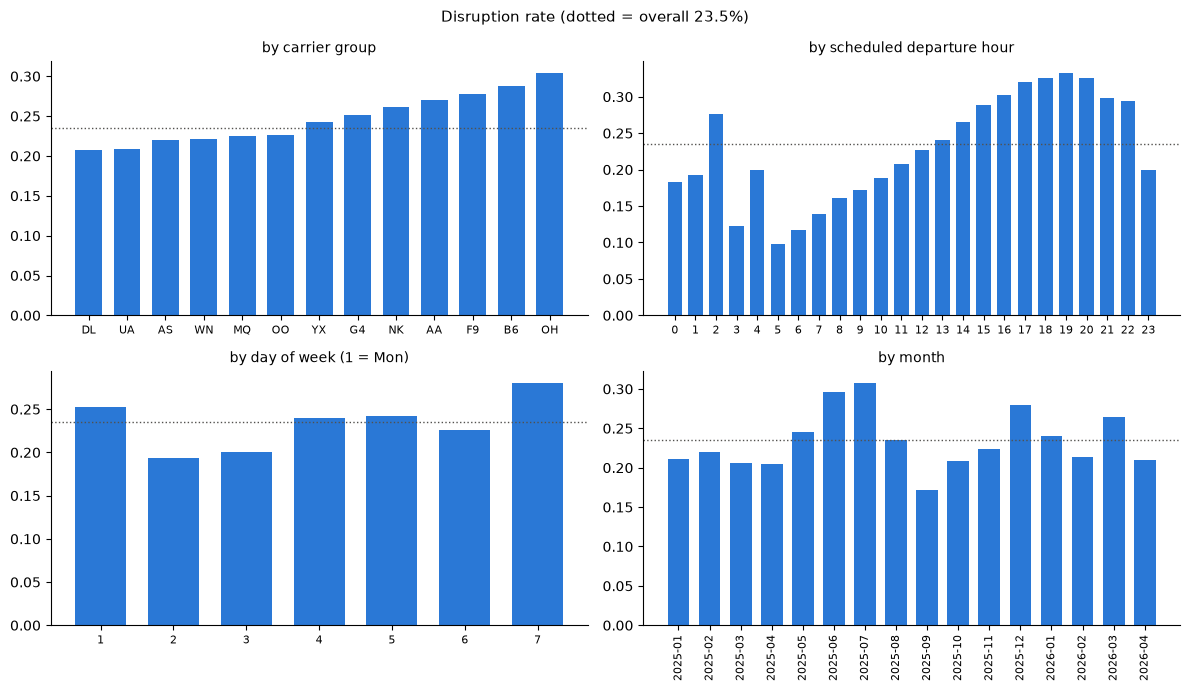

Origin airports with ≥3,000 sampled flights: 41; rate range 15.2% (HNL) – 30.1% (DFW)
Routes with ≥300 sampled flights: 221; rate 5th–95th percentile 14.9% – 34.1%


mean   size
        origin              
lowest  HNL     0.152   3922
        SLC     0.162   7730
        SMF     0.171   3665
        PDX     0.173   4008
        LAX     0.191  12446
highest MIA     0.279   7615
        LGA     0.290   9068
        DCA     0.292   9350
        ORD     0.294  22021
        DFW     0.301  20612

In [15]:
# E.1 Where and when are flights disrupted? (5% exploration sample; train + validation only)
ex = pd.read_parquet(config.SAMPLE_DIR / "explore_sample.parquet")
ex["month"] = ex["flight_date"].dt.month
base = ex["disrupted"].mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
def bar(ax, s, title, rot=0):
    ax.bar(s.index.astype(str), s.values, color="#2a78d6", width=0.7)
    ax.axhline(base, color="#52514e", lw=1, ls=":"); ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=rot, labelsize=8); ax.spines[["top", "right"]].set_visible(False)
bar(axes[0, 0], ex.groupby("carrier", observed=True)["disrupted"].mean().sort_values(), "by carrier group", 0)
bar(axes[0, 1], ex.groupby("dep_hour")["disrupted"].mean(), "by scheduled departure hour")
bar(axes[1, 0], ex.groupby("day_of_week")["disrupted"].mean(), "by day of week (1 = Mon)")
bar(axes[1, 1], ex.groupby(ex["flight_date"].dt.to_period("M").astype(str))["disrupted"].mean(), "by month", 90)
fig.suptitle(f"Disruption rate (dotted = overall {base:.1%})", fontsize=11); fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "explore_rates.png", dpi=150); plt.show()

big = ex.groupby("origin", observed=True)["disrupted"].agg(["mean", "size"]).query("size >= 3000").sort_values("mean")
route = ex.assign(route=ex.origin.astype(str) + "-" + ex.dest.astype(str)).groupby("route")["disrupted"].agg(["mean", "size"]).query("size >= 300")
print(f"Origin airports with ≥3,000 sampled flights: {len(big)}; rate range {big['mean'].min():.1%} ({big.index[0]}) – {big['mean'].max():.1%} ({big.index[-1]})")
print(f"Routes with ≥300 sampled flights: {len(route)}; rate 5th–95th percentile {route['mean'].quantile(.05):.1%} – {route['mean'].quantile(.95):.1%}")
display(pd.concat({"lowest": big.head(5), "highest": big.tail(5)}).round(3))


In [16]:
# E.2 Why are flights late? Delay-cause minutes by month (insight only: causes are flight-day outcomes, never features)
causes = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
mix = ex.groupby(ex["flight_date"].dt.to_period("M").astype(str))[causes].sum()
mix = mix.div(mix.sum(axis=1), axis=0)
display((100 * mix).round(1).rename(columns=lambda c: c.replace("_delay", "")).T)
comp = ex.assign(kind=np.select([ex.cancelled.eq(1), ex.diverted.eq(1)], ["cancelled", "diverted"], "late 15+"))
print((comp.loc[comp.disrupted.eq(1), "kind"].value_counts(normalize=True) * 100).round(1).to_string())


flight_date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
carrier,36.3,35.1,32.3,32.0,29.2,31.8,30.6,33.3,33.6,33.6,30.8,33.0,38.0,38.3,33.6,30.6
weather,8.1,6.0,6.8,6.0,6.8,6.8,7.5,7.2,6.6,3.3,4.7,6.3,9.7,6.0,6.6,5.5
nas,20.2,22.3,21.9,22.0,25.5,21.0,21.5,19.3,22.2,22.1,27.3,18.5,18.3,18.5,21.0,22.5
security,0.2,0.1,0.1,0.2,0.2,0.1,0.1,0.2,0.1,0.1,0.1,0.2,0.1,0.1,0.3,0.1
late_aircraft,35.2,36.5,39.0,39.8,38.3,40.3,40.3,40.0,37.5,40.8,37.1,42.0,33.9,37.2,38.6,41.3


kind
late 15+     92.5
cancelled     6.4
diverted      1.1


season
May–Aug         0.576
other months    0.659


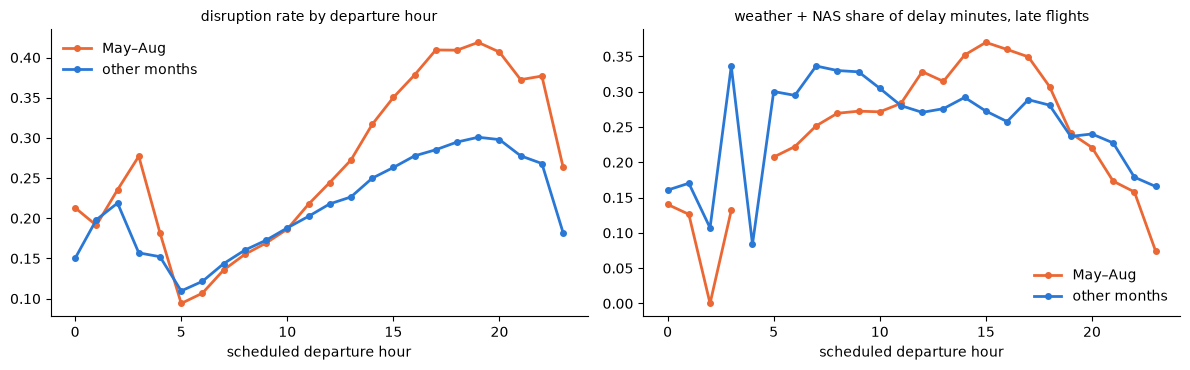

Rate at 06h vs 18h: {'May–Aug': '10.7% → 40.9%', 'other months': '12.2% → 29.5%'}
Weather + NAS share of delay minutes (%), late flights:


blk,<12h,12–15h,16h+
season,,,
May–Aug,25.8,34.5,27.6
other months,31.0,27.8,25.3


In [17]:
# E.3 The summer puzzle from the front pass: why does yesterday predict today less well in summer?
pop_day = pop.groupby("flight_date")["disrupted"].mean()
season = lambda idx: np.where(pd.DatetimeIndex(idx).month.isin([5, 6, 7, 8]), "May–Aug", "other months")
ac = pd.DataFrame({"rate": pop_day, "prev": pop_day.shift(1), "season": season(pop_day.index)}).dropna()
print(ac.groupby("season").apply(lambda g: g["rate"].corr(g["prev"])).round(3).rename("day-to-day correlation of the national rate").to_string())
# when in the day does it go wrong? share of each departure hour's flights disrupted, by season (full population)
prof = pop.assign(season=season(pop.flight_date)).groupby(["season", "dep_hour"])["disrupted"].mean().unstack(0)
wx = ex.assign(season=season(ex.flight_date)).query("arr_delay >= 15").groupby(["season", "dep_hour"])[["weather_delay", "nas_delay"]].sum()
wx = wx.div(ex.assign(season=season(ex.flight_date)).query("arr_delay >= 15").groupby(["season", "dep_hour"])[causes].sum().sum(axis=1), axis=0).sum(axis=1).unstack(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s, c in [("May–Aug", "#eb6834"), ("other months", "#2a78d6")]:
    axes[0].plot(prof.index, prof[s], color=c, lw=2, marker="o", ms=4, label=s)
    axes[1].plot(wx.index, wx[s], color=c, lw=2, marker="o", ms=4, label=s)
axes[0].set_title("disruption rate by departure hour", fontsize=10); axes[1].set_title("weather + NAS share of delay minutes, late flights", fontsize=10)
for a in axes: a.legend(frameon=False); a.spines[["top", "right"]].set_visible(False); a.set_xlabel("scheduled departure hour")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "explore_summer.png", dpi=150); plt.show()
print("Rate at 06h vs 18h:", {s: f"{prof.loc[6, s]:.1%} → {prof.loc[18, s]:.1%}" for s in prof.columns})
late = ex.assign(season=season(ex.flight_date), blk=pd.cut(ex.dep_hour, [-1, 11, 15, 23], labels=["<12h", "12–15h", "16h+"])).query("arr_delay >= 15")
g = late.groupby(["season", "blk"], observed=True)[causes].sum()
print("Weather + NAS share of delay minutes (%), late flights:"); display((100 * (g.weather_delay + g.nas_delay) / g.sum(axis=1)).round(1).unstack())


In [18]:
# E.4 Airport clustering by delay profile (k-means on standardized airport features; k by silhouette)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
g = pop.groupby("origin")
prof_hr = pop.assign(block=pd.cut(pop.dep_hour, [-1, 9, 14, 18, 23], labels=["early", "midday", "afternoon", "evening"])) \
             .groupby(["origin", "block"], observed=True)["disrupted"].mean().unstack()
air = pd.DataFrame({"flights": g.size(), "rate": g["disrupted"].mean(),
                    "summer_minus_winter": pop[pop.flight_date.dt.month.isin([6, 7, 8])].groupby("origin")["disrupted"].mean()
                                           - pop[pop.flight_date.dt.month.isin([12, 1, 2])].groupby("origin")["disrupted"].mean(),
                    "evening_minus_early": prof_hr["evening"] - prof_hr["early"],
                    # volume-adjusted volatility (critic m8): day-to-day variance minus the binomial variance p(1-p)/n
                    "day_to_day_sd": pop.groupby(["origin", "flight_date"])["disrupted"].agg(["mean", "size"]).groupby("origin").apply(
                        lambda x: np.sqrt(max(x["mean"].var() - (x["mean"].mean() * (1 - x["mean"].mean()) / x["size"]).mean(), 0)))}).dropna()
air = air[air.flights >= 5000]
X = StandardScaler().fit_transform(air.drop(columns="flights"))
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=config.SEED).fit_predict(X)) for k in range(2, 8)}
k = max(sil, key=sil.get)
air["cluster"] = KMeans(k, n_init=20, random_state=config.SEED).fit_predict(X)
print("silhouette by k:", {k_: round(v, 3) for k_, v in sil.items()}, "→ k =", k)
summary = air.groupby("cluster").agg(airports=("rate", "size"), flights=("flights", "sum"), rate=("rate", "mean"),
                                     summer_minus_winter=("summer_minus_winter", "mean"), evening_minus_early=("evening_minus_early", "mean"),
                                     day_to_day_sd=("day_to_day_sd", "mean"))
summary["examples"] = [", ".join(air[air.cluster == c].sort_values("flights", ascending=False).index[:6].astype(str)) for c in summary.index]
display(summary.round(3))


silhouette by k: {2: 0.303, 3: 0.282, 4: 0.243, 5: 0.248, 6: 0.244, 7: 0.238} → k = 2


,airports,flights,rate,summer_minus_winter,evening_minus_early,day_to_day_sd,examples
cluster,,,,,,,
0,53,2525210,0.182,0.024,0.124,0.093,"PHX, LAX, LAS, SEA, SFO, SLC"
1,110,6437666,0.241,0.033,0.203,0.139,"ORD, DEN, ATL, DFW, CLT, MCO"


In [19]:
# E.5 Which candidate inputs carry signal? Univariate check on the full population (training months only)
trn = pop[pop.period == "train"]
cand = ["dep_hour", "arr_hour", "day_of_week", "distance", "sched_elapsed_time", "origin_hour_sched", "origin_day_sched"] + DAY_BEFORE_FEATURES
uni = pd.DataFrame({"Spearman with target": trn[cand].corrwith(trn["disrupted"], method="spearman"),
                    "missing %": 100 * trn[cand].isna().mean()})
for c in ["carrier", "origin", "dest"]:   # categorical: spread of level rates (levels with ≥1,000 flights)
    r = trn.groupby(c)["disrupted"].agg(["mean", "size"]).query("size >= 1000")["mean"]
    uni.loc[c, "level-rate range"] = f"{r.min():.1%} – {r.max():.1%} ({len(r)} levels)"
display(uni.round(3))
print("Correlation among the three day-before rates:"); display(trn[DAY_BEFORE_FEATURES].corr().round(2))
# spot-check: explore-sample rates vs full population (SAS: results from a representative sample should generalize)
chk = pd.DataFrame({"sample": ex.groupby("carrier", observed=True)["disrupted"].mean(), "population": pop.groupby("carrier")["disrupted"].mean()})
print(f"Explore sample vs population, carrier rates: max |gap| = {100 * (chk['sample'] - chk['population']).abs().max():.2f} pp")


,Spearman with target,missing %,level-rate range
dep_hour,0.176,0.000,NaN
arr_hour,0.167,0.000,NaN
day_of_week,0.030,0.000,NaN
distance,0.007,0.000,NaN
sched_elapsed_time,0.011,0.000,NaN
origin_hour_sched,0.040,0.000,NaN
origin_day_sched,0.051,0.000,NaN
origin_prev_day,0.135,0.359,NaN
dest_prev_day,0.132,0.434,NaN
carrier_prev_day,0.134,0.240,NaN


Correlation among the three day-before rates:


,origin_prev_day,dest_prev_day,carrier_prev_day
origin_prev_day,1.00,0.37,0.52
dest_prev_day,0.37,1.00,0.52
carrier_prev_day,0.52,0.52,1.00


Explore sample vs population, carrier rates: max |gap| = 0.02 pp


In [20]:
# E.6 Anomalies: the extreme days (critic m7). Per-day lift is capped at 1 / that day's rate, so storm days limit lift
day = pop.groupby("flight_date").agg(flights=("disrupted", "size"), rate=("disrupted", "mean"))
canc_all = d[d.period.isin(["train", "valid"])].groupby("flight_date")["cancelled"].mean()   # all flights incl. tail-less
day["cancelled (all flights)"] = canc_all
day["max possible lift"] = 1 / day["rate"]
display(day.sort_values("rate", ascending=False).head(10).round(3))
print(f"Days with > 5% of all flights cancelled: {(canc_all > 0.05).sum()} · days with disruption rate > 50%: {(day.rate > 0.5).sum()} "
      f"· lowest-rate day {day.rate.idxmin().date()} ({day.rate.min():.1%})")
print("Daily-rate quantiles:", day.rate.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_dict())


,flights,rate,cancelled (all flights),max possible lift
flight_date,,,,
2026-01-25,16209,0.651,0.465,1.536
2026-03-16,20091,0.634,0.196,1.577
2026-01-26,17156,0.553,0.271,1.809
2025-11-09,20087,0.512,0.121,1.954
2025-11-30,21465,0.488,0.039,2.050
2026-03-15,20148,0.467,0.141,2.143
2025-03-16,20048,0.464,0.043,2.157
2025-02-16,18836,0.462,0.065,2.163
2025-01-06,18399,0.453,0.1,2.207


Days with > 5% of all flights cancelled: 35 · days with disruption rate > 50%: 4 · lowest-rate day 2025-01-28 (6.0%)
Daily-rate quantiles: {0.05: 0.11, 0.25: 0.167, 0.5: 0.217, 0.75: 0.286, 0.95: 0.407}


**What Explore found, and what it changes in Modify:**

| # | Finding (train + validation; sample confirmed on the full frame, carrier rates within 0.02 pp) | Consequence |
|---|---|---|
| X1 | **Time of day dominates**, and the slope is steepest in summer: 10.7% at 06h → 40.9% at 18h (May–Aug), against 12.2% → 29.5% in other months. Departure hour has the largest univariate signal (Spearman 0.18) | keep hour inputs; add **carrier × hour** and **origin × hour** history |
| X2 | **Delays propagate.** Late-arriving aircraft cause 34–42% of delay minutes every month, and the airline's own causes another 29–38%. Weather is only 3–10% *as recorded* (it also hides inside NAS delays, 18–27%) | the same flight number's recent record (**flight_w4**) and the carrier's day are worth more than a weather proxy |
| X3 | **Summer persistence is weaker:** the day-to-day correlation of the national rate is 0.58 in May–Aug vs 0.66 otherwise. Weather + NAS causes take a larger share of delay minutes for summer **afternoon** departures (12–15h: 34.5% vs 27.8% in other months; similar after 16h, 27.6% vs 25.3%), which points to afternoon convective weather. That's a hypothesis: the data has no weather observations | add **1-week and 4-week** windows, which carry over better than yesterday alone |
| X4 | **Airport delay profiles (descriptive only):** k-means on rate, summer−winter gap, evening−early gap and volume-adjusted day-to-day volatility. Silhouette is low (0.30 at the chosen k = 2, with k = 3–4 close behind), so the groups are a rough description, not segments: broadly, high-rate volatile hubs vs lower, steadier (mostly western) airports. See the E.4 table | not used as an input; origin/dest stay categorical, and airport × hour history captures the profile directly |
| X5 | Airport rates span 10.8–38.4% and routes 15–34% (5th–95th percentile). Disruptions are 92.5% late arrivals, 6.4% cancellations and 1.1% diversions | **route** history; the target definition is stable |
| X6 | The front-pass previous-day rates are missing for only 0.24–0.43% of flights (*revision 2: v1 said 24–43%, a ×100 slip caught by the critic*). Many rates rest on few flights, though (M.3 prints the < 20-flight shares), and the three rates correlate at only 0.37–0.52 | shrink rates toward a prior so thin cells don't give extreme rates; keep all three plus a **national** rate |
| X7 | **Extreme days** (E.6): 4 days have more than half of all flights disrupted. The worst, 2026-01-25 (a winter storm), had 65.1% disrupted and 46.5% cancelled, and 35 days had more than 5% of flights cancelled. Daily rates run from 11% to 41% (5th–95th percentile). Per-day lift can never exceed 1 / that day's rate, so these days cap lift | keep them (they are real and the team still has to choose); Assess also reports the gap without the 5% highest-rate days |

*Caveat (critic m3):* Explore used train **and validation** months, and Modify's inputs were designed from it. So validation-window gains in Modify and Model are somewhat optimistic. The sealed test summer in Assess is the only unbiased estimate.


---
# Modify

> SEMMA *Modify*: create, select and transform the inputs (SAS EM: Transform Variables, Replacement, Impute). Here that means one fixed decision clock, the history features Explore pointed to, and the transformations the non-tree models need. All code is in `src/flightdelay/modify.py` and unit-tested (`tests/test_modify.py`).

**Revision 2 (critic round 1):** day-grouped early stopping; arrival in ET = departure in ET + scheduled elapsed time, plus split-zone airport overrides; float64 accumulators and a contiguous-date assertion; log1p counts; end-to-end invariance tests (`test_build_frame_inputs_never_see_their_own_day_or_later`).

**The design choice that removes a whole class of leakage:** every history input is a **trailing window over earlier days**. Yesterday's flights count only if they were scheduled to land by **16:45 US Eastern**, which is the single national clock that critic round 2 asked for (N3: 17:00 ET minus a 15-minute reporting margin, time-zone- and DST-aware). Days D−2 and earlier count in full. A value for day D never sees day D, so no train-only target encoding is needed, and the same code produces test-period features at Assess time from strictly earlier days.

| Group | Inputs | Why (from Explore / the front pass) |
|---|---|---|
| Schedule | departure/arrival hour, weekday, distance, scheduled time, carrier, origin, dest, departure time in ET | the strong time-of-day gradient; carrier and airport level differences |
| Congestion (full schedule) | flights scheduled per origin-hour, origin-day, **dest-hour**, **carrier-day** | known in advance; built before any population filter (critic round 2, N2) |
| Calendar | days to the nearest US federal holiday | holiday travel peaks; `month` stays excluded (it encodes one year's weather) |
| Yesterday (16:45 ET) | origin, dest, carrier and **national** rate; origin count | day-to-day persistence (strongest outside summer) |
| Last week (D−7..D−2) | origin, dest, carrier, national | slower-moving spells, e.g. a run of storms or a carrier IT meltdown |
| Last four weeks (D−29..D−2) | **route**, **carrier × hour**, **origin × hour**, **this flight number** | the within-day structure that should help in summer, when yesterday says less |

**Transformations** (non-tree models only; LightGBM uses raw values and native categoricals):
- rare levels (fewer than 1,000 rows *in the fit sample*, i.e. about 8,700 flights a year at 800k) are pooled into an "infrequent" bucket, which also catches unseen airports;
- right-skewed counts (scheduled flights, window counts) are log1p-transformed (revision 2), then all numerics are standardized. A median imputer stays as a safeguard, though the v3 inputs have no missing values;
- history rates are shrunk toward the 2025 base rate (20 pseudo-flights), so thin airports and flight numbers don't produce extreme rates.

**Limitation (critic m2/N7):** one constant shrinkage prior (the 2025 base rate, 20 pseudo-flights) is used for every rate family and window, and only two families expose their counts. For a per-day *ranking* the effect is small, but the prior isn't tuned.

**Outliers:** the 18 rows with missing or non-positive scheduled time were dropped in the front pass. Long-haul distances (up to 5,095 mi) are real flights and are kept.

**Assumptions** (revision 2):
- **A-sched:** the BTS schedule for day D, including flights later cancelled, is what the team sees at 17:00 on D−1. Flights dropped from the schedule well in advance never appear in BTS.
- **Clock approximation:** arrival in ET is computed as departure in ET plus scheduled elapsed time. Time zones come from the state, with an override table for airports in split-zone states (ELP, RAP, the Florida panhandle, east Tennessee and others).


In [21]:
# M.1 Build the v3 feature set on the FULL train + validation schedule (src/flightdelay/modify.py), then filter
from flightdelay import modify
from flightdelay.features import known_by_cutoff
raw_m = load_flights(columns=modify.RAW_COLUMNS); raw_m["row_id"] = np.arange(len(raw_m), dtype="int32")
raw_m = assert_no_test_targets(raw_m[period(raw_m["flight_date"]).isin(["train", "valid"])])
fr = modify.build_frame(raw_m)
fr["year_month"] = fr["flight_date"].dt.to_period("M").astype(str); fr["period"] = period(fr["flight_date"])
assert len(fr) == len(pop)
print(f"v3 frame: {len(fr):,} flights × {len(modify.V3_FEATURES)} model inputs")
known = modify.known_by_clock(fr)
print(f"Share of flights known by 16:45 ET on their own day: {known.mean():.1%} (v2 local-17:00 rule: {known_by_cutoff(fr).mean():.1%})")
print(f"Flights the v2 local rule counted as known but that land after 16:45 ET: {(known_by_cutoff(fr) & ~known).mean():.1%}")
print("Destination offset from ET (hours) → flights:", fr["dest_offset_et"].value_counts().sort_index().to_dict())


v3 frame: 9,248,154 flights × 28 model inputs
Share of flights known by 16:45 ET on their own day: 48.6% (v2 local-17:00 rule: 57.2%)
Flights the v2 local rule counted as known but that land after 16:45 ET: 8.6%
Destination offset from ET (hours) → flights: {-6.0: 97436, -5.0: 64779, -4.0: 48670, -3.0: 1792438, -2.0: 931896, -1.0: 2508996, 0.0: 3776736, 1.0: 25564, 14.0: 981, 15.0: 658}


In [22]:
# M.2 Leakage audit of the final input list: every input, where it comes from, and when it is known
audit = pd.DataFrame([
    ("dep_hour, arr_hour, day_of_week, distance, sched_elapsed_time, carrier, origin, dest", "published schedule", "yes"),
    ("dep_min_et", "scheduled departure converted to Eastern time (national position in the day)", "yes"),
    ("origin_hour_sched, origin_day_sched, dest_hour_sched, carrier_day_sched", "counts on the FULL published schedule (incl. later cancellations)", "yes"),
    ("days_to_holiday", "US federal holiday calendar", "yes"),
    ("origin_d1, dest_d1, carrier_d1, nation_d1 (+ origin_d1_n)", "yesterday, flights scheduled to land by 16:45 ET", "yes (single national clock)"),
    ("origin_w1, dest_w1, carrier_w1, nation_w1", "complete days D-7 .. D-2", "yes"),
    ("route_w4, carrier_hour_w4, origin_hour_w4, flight_w4 (+ flight_w4_n)", "complete days D-29 .. D-2", "yes"),
    ("tail_number and anything from it; month; all flight-day outcomes; daily_airport_stats; airlines/airports aggregates", "—", "EXCLUDED"),
], columns=["inputs", "source", "known at 16:45 ET the day before?"]).set_index("inputs")
display(audit)
# empirical checks: (1) missingness never encodes the target; (2) no input is a near-copy of the target
miss = fr[modify.V3_NUMERIC].isna().mean()
corr = fr[modify.V3_NUMERIC].corrwith(fr["disrupted"], method="spearman").abs()
print(f"Inputs with any missing value: {list(miss[miss > 0].index) or 'none'} · largest |Spearman| with the target: {corr.max():.3f} ({corr.idxmax()})")


,source,known at 16:45 ET the day before?
inputs,,
"dep_hour, arr_hour, day_of_week, distance, sched_elapsed_time, carrier, origin, dest",published schedule,yes
dep_min_et,scheduled departure converted to Eastern time ...,yes
"origin_hour_sched, origin_day_sched, dest_hour_sched, carrier_day_sched",counts on the FULL published schedule (incl. l...,yes
days_to_holiday,US federal holiday calendar,yes
"origin_d1, dest_d1, carrier_d1, nation_d1 (+ origin_d1_n)","yesterday, flights scheduled to land by 16:45 ET",yes (single national clock)
"origin_w1, dest_w1, carrier_w1, nation_w1",complete days D-7 .. D-2,yes
"route_w4, carrier_hour_w4, origin_hour_w4, flight_w4 (+ flight_w4_n)",complete days D-29 .. D-2,yes
tail_number and anything from it; month; all flight-day outcomes; daily_airport_stats; airlines/airports aggregates,—,EXCLUDED


Inputs with any missing value: none · largest |Spearman| with the target: 0.211 (flight_w4)


In [23]:
# M.3 Does Modify help? Same LightGBM, same 800k stratified training sample, v2 (front-pass) vs v3 inputs.
# Revision 2: day-grouped early stopping (critic M1), 3 seeds, paired per-day lift difference with a 7-day-block interval.
from flightdelay import models
from flightdelay.metrics import block_bootstrap, day_holdout
import lightgbm as lgb
abl, gaps_m = [], []
print("Low-count shares that motivate shrinkage (critic M5):",
      {c: f"{(fr[c] < 20).mean():.1%}" for c in ["origin_d1_n", "flight_w4_n"]}, "of flights have < 20 flights behind the rate")
for w, (trr, var) in config.LC_WINDOWS.items():
    pool_w = fr[fr.flight_date.between(*trr)]; va_w = fr[fr.flight_date.between(*var)]
    tr_w = sampling.stratified_sample(pool_w, min(800_000, len(pool_w)), config.SAMPLE_STRATA, config.SEED)
    yv, dv = va_w["disrupted"].to_numpy(), va_w["flight_date"].to_numpy()
    daily_l = {}
    for label, feats in [("v2 front-pass inputs", SCHEDULE_FEATURES + DAY_BEFORE_FEATURES), ("v3 Modify inputs", modify.V3_FEATURES)]:
        Xt = tr_w[feats].copy(); Xv = va_w[feats].copy()
        for c in ["carrier", "origin", "dest"]:
            cats_c = pd.Index(sorted(Xt[c].astype(str).unique()))
            Xt[c] = pd.Categorical(Xt[c].astype(str), categories=cats_c); Xv[c] = pd.Categorical(Xv[c].astype(str).where(Xv[c].astype(str).isin(cats_c)), categories=cats_c)
        for seed in [config.SEED, config.SEED + 1, config.SEED + 2]:
            m = models.make("gradient boosting", seed)
            es = day_holdout(tr_w["flight_date"].to_numpy(), 0.10, seed)
            m.fit(Xt[~es], tr_w["disrupted"][~es], eval_set=[(Xt[es], tr_w["disrupted"][es])], callbacks=[lgb.early_stopping(50, verbose=False)])
            s = m.predict_proba(Xv, num_iteration=m.best_iteration_)[:, 1]
            daily_l[(label, seed)] = per_day(dv, yv, s, 0.02)[1]
            abl.append({"window": w, "inputs": label, "seed": seed, "trees": m.best_iteration_, **lcurve.metrics_row(yv, s, dv)})
    g = np.mean([daily_l[("v3 Modify inputs", sd)] - daily_l[("v2 front-pass inputs", sd)] for sd in [config.SEED, config.SEED + 1, config.SEED + 2]], axis=0)
    lo, hi = block_bootstrap(g)
    gaps_m.append({"window": w, "v3 − v2 per-day lift (3-seed mean)": g.mean(), "90% block lo": lo, "90% block hi": hi, "days better": (g > 0).mean()})
abl = pd.DataFrame(abl)
display(abl.groupby(["window", "inputs"])[["trees", "top2_lift", "top10_lift", "roc_auc", "log_loss"]].mean().round(4))
display(pd.DataFrame(gaps_m).set_index("window").round(3))
imp = pd.Series(m.booster_.feature_importance("gain"), index=modify.V3_FEATURES).sort_values(ascending=False)
print("Top 10 v3 inputs by gain (summer-window model, last seed):", ", ".join(f"{k} {v / imp.sum():.0%}" for k, v in imp.head(10).items()))


Low-count shares that motivate shrinkage (critic M5): {'origin_d1_n': '10.8%', 'flight_w4_n': '41.2%'} of flights have < 20 flights behind the rate


trees  top2_lift  top10_lift  roc_auc  \
window inputs                                                           
main   v2 front-pass inputs  212.3333     2.2072      1.8495   0.6903   
       v3 Modify inputs      116.6667     2.4175      1.9737   0.6964   
summer v2 front-pass inputs   91.0000     1.9737      1.7786   0.6835   
       v3 Modify inputs      147.3333     2.1682      1.8913   0.6934   

                             log_loss  
window inputs                          
main   v2 front-pass inputs    0.5010  
       v3 Modify inputs        0.4989  
summer v2 front-pass inputs    0.5525  
       v3 Modify inputs        0.5496

,v3 − v2 per-day lift (3-seed mean),90% block lo,90% block hi,days better
window,,,,
main,0.210,0.140,0.277,0.733
summer,0.194,0.144,0.243,0.764


Top 10 v3 inputs by gain (summer-window model, last seed): origin 14%, nation_d1 11%, dest 11%, carrier_d1 11%, flight_w4 10%, nation_w1 9%, dep_hour 6%, day_of_week 5%, arr_hour 4%, days_to_holiday 3%


**Modify results (revision 2):**
- **The single clock is stricter:** 48.6% of flights count as "known by 16:45 ET" on their own day, against 57.2% under the front-pass local-17:00 rule. 8.6% of flights were counted as "known" by the old rule but actually land after 16:45 ET (mostly western arrivals after 13:45 local).
- **Coverage:** destination offsets run from −6 h (Hawaii in summer) to +15 h (Guam/Saipan, 1.6k flights). Arrival in ET is now computed from departure in ET plus scheduled elapsed time, which removes the date-line and westbound-hop errors the critic found.
- **Leakage audit:** every input is schedule-based or a trailing window over strictly earlier days, and none is missing after shrinkage. The strongest single input is flight_w4 (Spearman 0.21), far from a near-copy of the target. End-to-end tests check that truncating later days, or flipping day D's outcomes, never changes an earlier or day-D input. The critic re-ran both checks on real data and found zero differences.
- **Why shrink:** 10.8% of flights have fewer than 20 flights behind their origin d−1 rate, and 41.2% behind their own flight number's 4-week rate.
- **Modify pays off:** the same LightGBM on the same 800k sample, 3 seeds, day-grouped early stopping:

| Window | v2 → v3 per-day top-2% lift | Paired daily gain (90% 7-day-block interval) | Days better | AUC | Log-loss |
|---|---|---|---|---|---|
| Main | 2.21 → **2.42** | **+0.21** (+0.14 to +0.28) | 73% | 0.690 → 0.696 | 0.501 → 0.499 |
| Summer | 1.97 → **2.17** | **+0.19** (+0.14 to +0.24) | 76% | 0.684 → 0.693 | 0.553 → 0.550 |

  Calibration (log-loss) now improves too. In revision 1 it got worse in summer, a symptom of the early-stopping flaw. The inputs with the largest gain are origin, the national and carrier d−1 rates, dest, flight_w4 and the national week rate.
- *Caveat:* these are validation-window gains on months Explore had seen (see the Explore caveat). The sealed test is the clean check.


---
# Model

> SEMMA *Model*, with Enterprise Miner's three classic model nodes (**Regression**, **Decision Tree**, **Neural Network**) plus **Gradient Boosting**, which is also an EM node. Everything is fit on the 2025 training months, using the 72% stratified sample (5.0M rows) for gradient boosting and the 800k stratified sample for the other three (Sample S.2/S.3). Settings are tuned on Jan–Apr 2026 validation and then re-run with the chosen settings on the summer check (Jan–Apr 2025 → May–Aug 2025). The two simple rules from the front pass are the benchmark. Test months are never loaded.

The fitting runs in `scripts/run_model.py` (about 5 min), and this section shows the tables that script saved (`reports/tables/model_*.csv`). The script also applies the pre-declared champion rule and writes the choice to `model_chosen.json`, which Assess checks. Set `RUN_MODEL = True` to re-run it from here.

| Node | Implementation | Tuned on validation |
|---|---|---|
| Regression | one-hot logistic regression (`sklearn`), rare levels pooled, numerics standardized | C ∈ {0.1, 1} |
| Decision Tree | CART (`sklearn`), min 500 flights per leaf | depth ∈ {8, 12, 16} |
| Neural Network | MLP (`sklearn`), Adam; epochs chosen on a held-out 10% of training **days** (revision 3, critic round 2, N1) | (64, 32) with α = 1e-4, or (128, 64) with α = 1e-3 |
| Gradient Boosting | LightGBM, native categoricals; trees set by early stopping on a held-out 10% of training **days** | 63 leaves, or 255 leaves with min 500 per leaf |


In [24]:
# MO.1 Tuning on validation (main window), then the chosen settings re-run on the summer check
import json, subprocess
RUN_MODEL = False
if RUN_MODEL:
    subprocess.run([sys.executable, "scripts/run_model.py", str(SAMPLE_RATE)], check=True)   # rate from S.2
T = config.PROJECT_DIR / "reports" / "tables"
tuning = pd.read_csv(T / "model_tuning.csv")
display(tuning.drop(columns=["seconds"]).set_index(["window", "model", "params"]).round(4))


train rows  \
window model               params                                                      
main   logistic regression {"C": 0.1}                                         800000   
                           {"C": 1.0}                                         800000   
       decision tree       {"max_depth": 8}                                   800000   
                           {"max_depth": 12}                                  800000   
                           {"max_depth": 16}                                  800000   
       neural network      {"hidden": [64, 32], "alpha": 0.0001}              800000   
                           {"hidden": [128, 64], "alpha": 0.001}              800000   
       gradient boosting   {"num_leaves": 63}                                5032161   
                           {"num_leaves": 255, "min_child_samples": 500}     5032161   
summer logistic regression {"C": 0.1}                                         800000   
       decision tree       {"max_depth": 16}                                  800000   
       neural network      {"hidden": [128, 64], "alpha": 0.001}              800000   
       gradient boosting   {"num_leaves": 255, "min_child_samples": 500}     1601889   

                                                                          top2_lift  \
window model               params                                                     
main   logistic regression {"C": 0.1}                                        2.4420   
                           {"C": 1.0}                                        2.4390   
       decision tree       {"max_depth": 8}                                  2.0805   
                           {"max_depth": 12}                                 2.0792   
                           {"max_depth": 16}                                 2.0862   
       neural network      {"hidden": [64, 32], "alpha": 0.0001}             2.4625   
                           {"hidden": [128, 64], "alpha": 0.001}             2.4680   
       gradient boosting   {"num_leaves": 63}                                2.4630   
                           {"num_leaves": 255, "min_child_samples": 500}     2.4695   
summer logistic regression {"C": 0.1}                                        2.2266   
       decision tree       {"max_depth": 16}                                 1.8137   
       neural network      {"hidden": [128, 64], "alpha": 0.001}             2.0707   
       gradient boosting   {"num_leaves": 255, "min_child_samples": 500}     2.1390   

                                                                          top2_precision  \
window model               params                                                          
main   logistic regression {"C": 0.1}                                             0.5393   
                           {"C": 1.0}                                             0.5388   
       decision tree       {"max_depth": 8}                                       0.4560   
                           {"max_depth": 12}                                      0.4581   
                           {"max_depth": 16}                                      0.4586   
       neural network      {"hidden": [64, 32], "alpha": 0.0001}                  0.5411   
                           {"hidden": [128, 64], "alpha": 0.001}                  0.5414   
       gradient boosting   {"num_leaves": 63}                                     0.5398   
                           {"num_leaves": 255, "min_child_samples": 500}          0.5401   
summer logistic regression {"C": 0.1}                                             0.5890   
       decision tree       {"max_depth": 16}                                      0.4843   
       neural network      {"hidden": [128, 64], "alpha": 0.001}                  0.5511   
       gradient boosting   {"num_leaves": 255, "min_child_samples": 500}          0.5736   

                                                                  

In [25]:
# MO.2 Model comparison vs the two simple rules; champion = best mean per-day top-2% lift over the two windows
comp = pd.read_csv(T / "model_comparison.csv")
gap = pd.read_csv(T / "model_gap_vs_rule.csv")
display(comp.pivot_table(index="scorer", columns="window", values=["top2_lift", "top2_precision", "top10_lift", "roc_auc", "pr_auc"]).round(3)
            .sort_values(("top2_lift", "main"), ascending=False))
display(gap.set_index(["window", "model"]).round(3))
models_only = comp[~comp.scorer.str.contains("rule") & ~comp.scorer.str.contains("800k")]   # equal-n row is a check, not a candidate
mean_lift = models_only.groupby("scorer")["top2_lift"].mean().sort_values(ascending=False)
CHAMPION = mean_lift.index[0]
chosen = json.load(open(T / "model_chosen.json"))
assert chosen["champion"] == CHAMPION and abs(chosen["sample_rate"] - SAMPLE_RATE) < 1e-9   # script and notebook agree
print("Mean per-day top-2% lift over main + summer:", mean_lift.round(3).to_dict())
print("Champion (pre-declared rule, written by run_model.py):", CHAMPION, "· boosting sample rate", chosen["sample_rate"])


pr_auc        roc_auc        top10_lift  \
window                             main summer    main summer       main   
scorer                                                                     
gradient boosting                 0.406  0.433   0.698  0.689      1.992   
neural network                    0.410  0.413   0.695  0.674      1.990   
logistic regression               0.414  0.452   0.693  0.701      1.973   
gradient boosting (800k)          0.402  0.431   0.695  0.686      1.970   
decision tree                     0.363  0.388   0.667  0.645      1.745   
day-before rule                   0.355  0.328   0.623  0.575      1.623   
day-before rule (v2 local clock)  0.359  0.330   0.628  0.583      1.622   
schedule rule                     0.304  0.394   0.610  0.661      1.482   

                                        top2_lift        top2_precision         
window                           summer      main summer           main summer  
scorer                                                                          
gradient boosting                 1.881     2.470  2.139          0.540  0.574  
neural network                    1.806     2.468  2.071          0.541  0.551  
logistic regression               1.928     2.442  2.227          0.539  0.589  
gradient boosting (800k)          1.870     2.421  2.155          0.532  0.576  
decision tree                     1.622     2.086  1.814          0.459  0.484  
day-before rule                   1.363     1.950  1.440          0.436  0.379  
day-before rule (v2 local clock)  1.367     1.891  1.392          0.421  0.365  
schedule rule                     1.655     1.560  1.741          0.357  0.471

best rule    gap   lo90   hi90  \
window model                                                            
main   logistic regression       day-before rule  0.492  0.392  0.589   
       decision tree             day-before rule  0.136 -0.025  0.291   
       neural network            day-before rule  0.518  0.360  0.657   
       gradient boosting         day-before rule  0.520  0.371  0.658   
       gradient boosting (800k)  day-before rule  0.472  0.323  0.610   
summer logistic regression         schedule rule  0.486  0.358  0.629   
       decision tree               schedule rule  0.073 -0.043  0.191   
       neural network              schedule rule  0.330  0.234  0.418   
       gradient boosting           schedule rule  0.398  0.319  0.486   
       gradient boosting (800k)    schedule rule  0.415  0.327  0.506   

                                 days better  
window model                                  
main   logistic regression             0.800  
       decision tree                   0.625  
       neural network                  0.817  
       gradient boosting               0.792  
       gradient boosting (800k)        0.767  
summer logistic regression             0.854  
       decision tree                   0.569  
       neural network                  0.789  
       gradient boosting               0.813  
       gradient boosting (800k)        0.870

Mean per-day top-2% lift over main + summer: {'logistic regression': 2.334, 'gradient boosting': 2.304, 'neural network': 2.269, 'decision tree': 1.95}
Champion (pre-declared rule, written by run_model.py): logistic regression · boosting sample rate 0.72


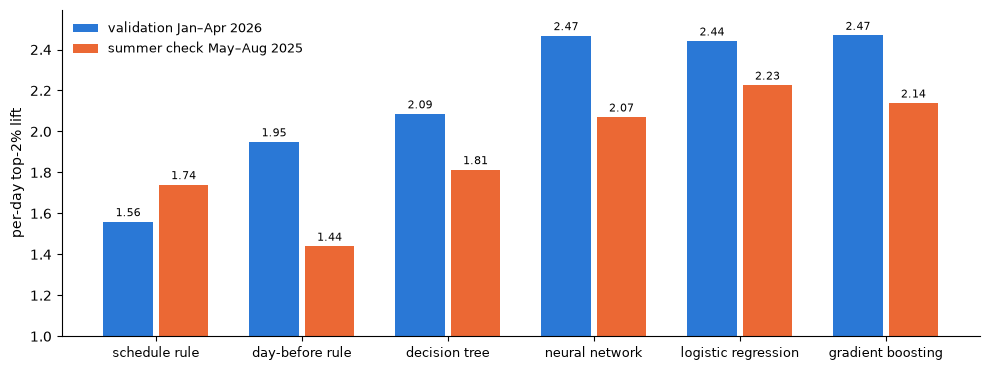

In [26]:
# MO.3 Figure: per-day top-2% lift by scorer and window
order = ["schedule rule", "day-before rule", "decision tree", "neural network", "logistic regression", "gradient boosting"]
fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.38
for k, (win, c) in enumerate([("main", "#2a78d6"), ("summer", "#eb6834")]):
    v = comp[comp.window == win].set_index("scorer").reindex(order)["top2_lift"]
    bars = ax.bar(np.arange(len(order)) + (k - 0.5) * w, v, width=w - 0.04, color=c,
                  label={"main": "validation Jan–Apr 2026", "summer": "summer check May–Aug 2025"}[win])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(np.arange(len(order)), order, fontsize=9); ax.set_ylabel("per-day top-2% lift"); ax.set_ylim(1, None)
ax.legend(frameon=False, fontsize=9); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "model_comparison.png", dpi=150); plt.show()


**Model results (revision 4; validation and summer check only, test still sealed):**

| Per-day top-2% lift (precision) | Main → Jan–Apr 2026 | Summer check → May–Aug 2025 | Mean |
|---|---|---|---|
| Schedule rule | 1.56 (0.36) | **1.74** (0.47) | — |
| Day-before rule (16:45 ET clock) | **1.95** (0.44) | 1.44 (0.38) | — |
| *Day-before rule, front-pass local clock (reported only)* | *1.89* | *1.39* | — |
| Decision tree (depth 16, 800k) | 2.09 (0.46) | 1.81 (0.48) | 1.95 |
| Neural network (128-64, 800k) | **2.47** (0.54) | 2.07 (0.55) | 2.27 |
| *Gradient boosting at 800k (equal-n check)* | *2.42 (0.53)* | *2.16 (0.58)* | *2.29* |
| Gradient boosting (255 leaves, 72% sample = 5.0M rows) | **2.47** (0.54) | 2.14 (0.57) | 2.30 |
| **Logistic regression (C = 0.1, 800k)** | 2.44 (0.54) | **2.23** (0.59) | **2.334 → champion** |

- **Champion: logistic regression, by the pre-declared rule. It is statistically tied with boosting, not clearly better.** The critic's paired per-day comparison (regression minus boosting) gives −0.03 in the main window (90% interval −0.09 to +0.04) and +0.09 in summer (+0.02 to +0.16). Each wins about half the days, and boosting's seed-to-seed SD is about 0.03. The rule picks the regression, so Assess tests the regression. Boosting is reported alongside as the runner-up, descriptive only, and never swapped in after the fact. The regression has also won in every revision (with f = 72%, f = 100%, row-random early stopping and both network fixes), so the choice isn't fragile.
- **Equal sample size (800k):** regression 2.44 / 2.23 against boosting 2.42 / 2.16. The direction favours the regression, but the main-window difference is inside the noise. Boosting's edge in the main window comes mostly from extra rows.
- **The SAS lesson, qualified:** once Modify has turned history into well-shrunk rates, an additive model on an 800k sample performs as well as a 5M-row ensemble.
- **The neural network gained most from the critic fixes.** Epochs are now chosen on held-out *days* (round 2, N1), and Adam runs continuously over shuffled batches (round 3, R3-1). Its lift rises from 2.33 to 2.47 (main) and from 1.88 to 2.07 (summer). It ties boosting in winter–spring but generalizes less well to summer.
- **The decision tree is the only model whose interval over the better rule covers 0** in both windows. Every other model beats the better simple rule in both windows; the champion's summer gap is +0.49 (+0.36 to +0.63), better on 85% of days.
- **Tuning choices are within the noise:** boosting at 63 vs 255 leaves differs by 0.006, the network's two settings by 0.006, tree depths by 0.007 and regression C by 0.003. The chosen settings are harmless, but they aren't meaningfully "better".
- **What the summer check rehearses:** fit-then-score on a new season, but not the train + validation refit, and Explore had seen those months. Its +0.49 gap is therefore an optimistic preview. T2 stays at the pre-registered +0.15 and is not raised.


---
# Assess

> SEMMA *Assess*: judge the models on data they've never seen, the way the business will use them. Enterprise Miner's Model Comparison node reports lift, gains and ROC side by side. Here the test months (**May–Aug 2026**) are unsealed **once**, by `scripts/run_assess.py`.

**Unsealing protocol:**
1. Model-stage code and choices are frozen **before** the run. `run_assess.py` writes a SHA-256 fingerprint of `src/`, `scripts/` and the Model choice to `reports/tables/assess_freeze.json` before it reads any test row, and refuses a second completed run.
2. Every model is refit with its validation-chosen settings on train + validation (Jan 2025 – Apr 2026), following the refit policy.
3. Test-period inputs are built on the full timeline, so they use only days *before* each flight date.
4. Every test flight is scored once.
5. The pre-registered targets T1–T3 (Sample S.5) are checked as written.


In [27]:
# AS.1 Results on the sealed test months (single run; tables written by scripts/run_assess.py)
RUN_ASSESS = False      # the one-time run already happened; re-running reproduces it (same seeds) but is not a new test
if RUN_ASSESS:
    subprocess.run([sys.executable, "scripts/run_assess.py"], check=True)
res = pd.read_csv(T / "assess_results.csv", index_col=0)
display(res.round(3).sort_values("top2_lift", ascending=False))
display(pd.read_csv(T / "assess_gap_vs_rule.csv", index_col=0).round(3))
display(pd.read_csv(T / "assess_targets.csv", index_col=0))


,top2_lift,top2_precision,top10_lift,top10_precision,roc_auc,pr_auc
scorer,,,,,,
neural network,2.461,0.638,2.042,0.540,0.718,0.472
gradient boosting,2.435,0.632,2.065,0.547,0.721,0.472
logistic regression,2.386,0.626,2.026,0.538,0.718,0.471
decision tree,2.164,0.562,1.883,0.499,0.698,0.442
schedule rule,1.699,0.466,1.607,0.439,0.668,0.397
day-before rule,1.600,0.421,1.401,0.373,0.583,0.338
day-before rule (v2 local clock),1.529,0.402,1.403,0.373,0.590,0.340


,best rule,gap,lo90,hi90,days better
model,,,,,
logistic regression,schedule rule,0.686,0.525,0.856,0.911
decision tree,schedule rule,0.465,0.277,0.658,0.748
neural network,schedule rule,0.761,0.582,0.951,0.919
gradient boosting,schedule rule,0.735,0.543,0.933,0.935


,result,met
target,,
T1 champion beats the better rule (90% interval > 0),"gap +0.686 [+0.525, +0.856] vs schedule rule",True
T2 gap >= +0.15,+0.686,True
T3 T1 with tail-less cancellations scored as disrupted,"gap +0.685 [+0.523, +0.855] vs schedule rule",True
(robustness) T1 without the 5% highest-rate days,"gap +0.722 [+0.563, +0.898] on 116 days",True


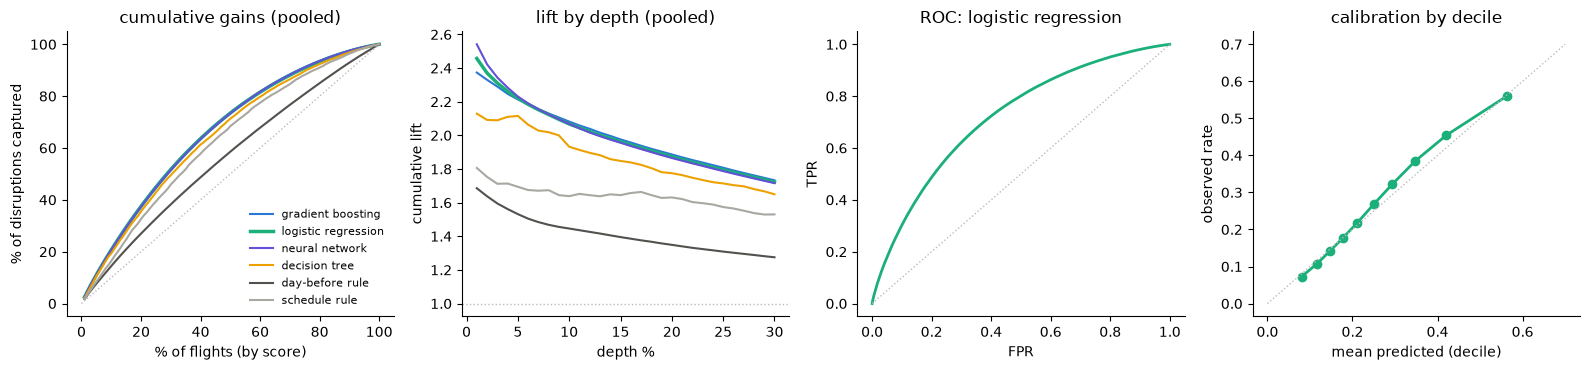

In [28]:
# AS.2 SAS-style assessment charts for every scorer: cumulative gains, lift by depth, ROC (champion), calibration
gains = pd.read_csv(T / "assess_gains.csv", index_col=0); roc = pd.read_csv(T / "assess_roc.csv"); cal = pd.read_csv(T / "assess_calibration.csv")
champ = json.load(open(T / "model_chosen.json"))["champion"]
cols = {"gradient boosting": "#2a78d6", "logistic regression": "#1baf7a", "neural network": "#6250d6", "decision tree": "#eda100",
        "day-before rule": "#52514e", "schedule rule": "#a8a7a1"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for n, c in cols.items():
    lw = 2.5 if n == champ else 1.5
    axes[0].plot(100 * gains.index, 100 * gains[n], color=c, lw=lw, label=n)
    axes[1].plot(100 * gains.index[:30], gains[n].iloc[:30] / gains.index[:30], color=c, lw=lw)
axes[0].plot([0, 100], [0, 100], color="#bbb", lw=1, ls=":"); axes[0].set(xlabel="% of flights (by score)", ylabel="% of disruptions captured", title="cumulative gains (pooled)")
axes[1].axhline(1, color="#bbb", lw=1, ls=":"); axes[1].set(xlabel="depth %", ylabel="cumulative lift", title="lift by depth (pooled)")
axes[2].plot(roc.fpr, roc.tpr, color=cols[champ], lw=2); axes[2].plot([0, 1], [0, 1], color="#bbb", lw=1, ls=":"); axes[2].set(xlabel="FPR", ylabel="TPR", title=f"ROC: {champ}")
axes[3].plot(cal.mean_score, cal.observed, color=cols[champ], marker="o", lw=2); axes[3].plot([0, 0.7], [0, 0.7], color="#bbb", lw=1, ls=":")
axes[3].set(xlabel="mean predicted (decile)", ylabel="observed rate", title="calibration by decile")
axes[0].legend(frameon=False, fontsize=8)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "assess_charts.png", dpi=150); plt.show()


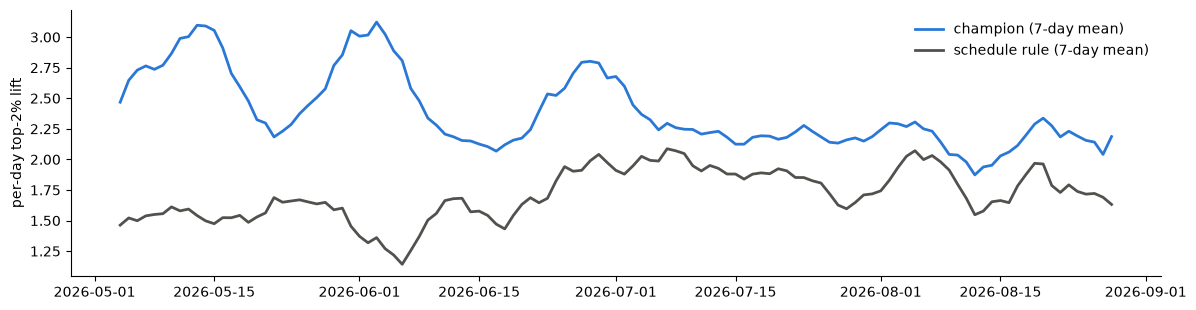

,rate,logistic regression top2_lift,schedule rule top2_lift
month,,,
2026-05,0.223,2.622,1.553
2026-06,0.271,2.522,1.588
2026-07,0.304,2.237,1.863
2026-08,0.284,2.165,1.789


,flights,rate,top2_lift,roc_auc
carrier,,,,
OH,84237,0.341,1.732,0.693
B6,87651,0.332,1.916,0.734
MQ,116993,0.211,1.940,0.665
AA,348675,0.305,1.985,0.703
YX,126451,0.250,2.034,0.700
F9,76703,0.306,2.213,0.685
WN,482892,0.314,2.281,0.755
DL,367516,0.222,2.412,0.693
G4,46427,0.294,2.501,0.707


In [29]:
# AS.3 Where does it work? Per-day lift over the summer, by month and by carrier (champion)
dl = pd.read_csv(T / "assess_daily_lift.csv", parse_dates=["date"])
fig, ax = plt.subplots(figsize=(12, 3.2))
for c, col in zip(dl.columns[1:], ["#2a78d6", "#52514e"]):
    ax.plot(dl.date, dl[c].rolling(7, center=True).mean(), color=col, lw=2, label=f"{c} (7-day mean)")
ax.set_ylabel("per-day top-2% lift"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "assess_daily.png", dpi=150); plt.show()
display(pd.read_csv(T / "assess_by_month.csv", index_col=0).round(3))
display(pd.read_csv(T / "assess_by_carrier.csv", index_col=0).sort_values("top2_lift").round(3))


**Assess verdict: the test summer (May–Aug 2026, 2,455,116 flights over 123 days, scored once; freeze fingerprint `d61fb8986e66c36d`).**

| Per-day top-2% lift (precision) | Test summer 2026 | Summer check 2025 (validation) |
|---|---|---|
| Schedule rule (**better rule on test**) | 1.70 (0.47) | 1.74 |
| Day-before rule (16:45 ET) | 1.60 (0.42) | 1.44 |
| Decision tree | 2.16 (0.56) | 1.81 |
| **Logistic regression (champion)** | **2.39 (0.63)** | 2.23 |
| Gradient boosting *(runner-up)* | 2.44 (0.63) | 2.14 |
| Neural network | 2.46 (0.64) | 2.07 |

**Pre-registered targets (Sample S.5): all met.**

| Target | Result | Met |
|---|---|---|
| T1: champion beats the better rule, 90% block interval > 0 | **+0.69** (+0.53 to +0.86) vs the schedule rule; better on **91%** of days | ✅ |
| T2: gap ≥ +0.15 | +0.69 | ✅ |
| T3: T1 with tail-less cancellations scored as disrupted | +0.69 (+0.52 to +0.86) | ✅ |
| Robustness: without the 5% highest-rate days | +0.72 (+0.56 to +0.90), 116 days | ✅ |

**What the care team gets:** of the ~380 flights it contacts each evening, **63% are actually disrupted**, against 27% of all flights in the test summer and 47% under the best simple rule. That's about 60 more disrupted flights caught per day for the same effort.

**Honest reading:**
- **The champion rule picked logistic regression, and on the test summer the neural network (2.46) and boosting (2.44) did slightly better** (+0.05 to +0.08). The validation tie (Model) carried over as a tie; the ranking among the three flexible models isn't stable across seasons. The champion is not swapped after unsealing. All three clear every target, so the decision doesn't hinge on the choice.
- **The test gap (+0.69) is larger than the summer rehearsal's (+0.49)** because the best simple rule did worse in 2026 (1.70 vs 1.74) while the models did better. The sealed result is not the optimistic one: the targets were set conservatively, and the test was harder for the rules, not easier for the models.
- **Ranking quality is solid, calibration is good but not perfect.** Pooled AUC is 0.718. By decile, the predicted rate tracks the observed one closely at the ends (8.0% vs 7.3% in the lowest decile, 56.3% vs 56.0% in the highest), with up to 4 pp under-prediction in deciles 6–8. The test summer ran hotter (27% disrupted) than training (23.5%). The ranking, which is what the team uses, isn't affected.
- **Lift fades through the summer:** 2.62 (May) → 2.52 (June) → 2.24 (July) → 2.17 (August), while the schedule rule improves. Late-summer convective days are harder to call the evening before, which is consistent with Explore X3. The monitoring plan watches the 7-day lift.
- **By carrier** (12 with ≥ 20k test flights), lift ranges from 1.73 (OH) to 2.94 (AS) and is above 1.9 for 11 of the 12. The carriers with the highest base rates (OH, B6, AA) have the lowest lift, partly because the lift ceiling is 1 / rate.


---
# Score / deploy

> SEMMA ends at Assess, but Enterprise Miner's **Score** node turns the champion into code that scores new data. The Python equivalent lives in `deployment/`:
> - `models/champion.joblib` and `models/manifest.json`: the champion refit on Jan 2025 – Apr 2026.
> - `deployment/score.py`: batch scoring. For a date D it rebuilds the inputs from the flight table, blanking day D's outcomes first, scores **every** scheduled flight (tail numbers aren't known the evening before) and writes the ranked list with the top 2% flagged.
> - `deployment/app.py`: a Streamlit demo that replays the test summer ("which flights would the team have called?").
> - `deployment/model_card.md` and `deployment/monitoring_plan.md`.


In [30]:
# SC.1 Batch-score one test day with the deployment code and check it reproduces the Assess scores
sys.path.insert(0, str(config.PROJECT_DIR / "deployment"))
from score import score_date
ranked = score_date("2026-07-03")
top_saved = pd.read_parquet(config.PROJECT_DIR / "deployment" / "test_period_top5pct.parquet")
saved = top_saved[top_saved.flight_date == "2026-07-03"].nsmallest(20, "rank")
print(f"{len(ranked):,} flights scored on 2026-07-03; {int(ranked.selected.sum())} selected")
display(ranked.head(10))
key = ["carrier", "flight_number", "origin", "sched_dep_time"]
overlap = len(set(map(tuple, ranked.head(20)[key].astype(str).values)) & set(map(tuple, saved[key].astype(str).values)))
print(f"Top-20 overlap with the Assess run on the same day: {overlap}/20 "
      "(differences come only from scoring the tail-less flights too, which Assess excluded)")


20,393 flights scored on 2026-07-03; 408 selected


,flight_date,carrier,flight_number,origin,dest,sched_dep_time,sched_arr_time,risk,selected
822955,2026-07-03,WN,673,BNA,SFO,1715,1955,0.864036,True
826380,2026-07-03,WN,4772,SAN,SFO,2010,2150,0.862663,True
824577,2026-07-03,WN,4670,DEN,SFO,1830,2020,0.845007,True
824129,2026-07-03,AA,1620,ORD,SFO,1809,2056,0.835324,True
826297,2026-07-03,WN,4397,LAS,SFO,2005,2135,0.833110,True
825553,2026-07-03,AA,1430,DFW,SFO,1928,2110,0.831609,True
827683,2026-07-03,WN,4303,DEN,SFO,2140,2325,0.828597,True
825676,2026-07-03,F9,3383,SAN,SFO,1935,2130,0.816498,True
820169,2026-07-03,WN,1101,BWI,SFO,1450,1730,0.809576,True
826803,2026-07-03,F9,2677,ONT,SFO,2036,2213,0.808661,True


Top-20 overlap with the Assess run on the same day: 20/20 (differences come only from scoring the tail-less flights too, which Assess excluded)


**Scoring package check.** The batch scorer rebuilds day D's inputs from the flight table, with D's own outcomes blanked, and ranks every scheduled flight. On 2026-07-03 its top 20 match the Assess ranking for that day (the line above gives the overlap; any difference comes only from also scoring flights without a tail number). So the deployed code reproduces the evaluated model.

**Deliverables:** `models/champion.joblib` and `manifest.json` (code fingerprint, test lift, inputs, clock); `deployment/score.py`; `deployment/app.py` (`streamlit run deployment/app.py`); `deployment/model_card.md`; `deployment/monitoring_plan.md`; and the SAS OnDemand rebuild guide `reports/sas_ondemand_guide.md`.
